# ReneWind – Wind Turbine Failure Prediction
### Neural Network Classification Project

**Goal:** Build a model that predicts generator failure in wind turbines so that maintenance teams can repair components *before* they fail, reducing overall costs.

---
**Cost structure (important for choosing our evaluation metric):**
| Prediction | Reality | Outcome |
|---|---|---|
| Failure (1) | Failure (1) | **True Positive** → Repair cost (moderate) |
| No Failure (0) | Failure (1) | **False Negative** → Replacement cost (highest!) |
| Failure (1) | No Failure (0) | **False Positive** → Inspection cost (lowest) |

Because **missing a real failure is the most expensive outcome**, we want a model that catches as many real failures as possible → **Recall** is our primary metric.


## 1. Import Libraries

In [92]:
# Standard data libraries
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, recall_score, precision_score, f1_score
)

# Neural network
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Reproducibility
import random, time
SEED = 1
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("All libraries loaded!")


TensorFlow version: 2.20.0
All libraries loaded!


## 2. Load the Data

In [93]:
from google.colab import drive
drive.mount('/content/drive') # Mount to a directory, not a file

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [94]:
import pandas as pd
# loading data into a pandas dataframe
df = pd.read_csv('/content/drive/MyDrive/Train.csv')
df_test = pd.read_csv('/content/drive/MyDrive/Test.csv')

# creating a copy of the data
data = df.copy()

In [95]:
# Working copies (keeps originals intact)
data      = df.copy()
data_test = df_test.copy()

print("Training set shape:", df.shape)
print("Test set shape    :", df_test.shape)


Training set shape: (20000, 41)
Test set shape    : (5000, 41)


## 3. Data Overview

### Checking the shape of the dataset

In [96]:
# Rows and columns – training data
df.shape


(20000, 41)

In [97]:
# Rows and columns – test data
df_test.shape


(5000, 41)

### First few rows

In [98]:
data.head()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


In [99]:
data_test.head()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613489,-3.819640,2.202302,1.300420,-1.184929,-4.495964,-1.835817,4.722989,1.206140,-0.341909,...,2.291204,-5.411388,0.870073,0.574479,4.157191,1.428093,-10.511342,0.454664,-1.448363,0
1,0.389608,-0.512341,0.527053,-2.576776,-1.016766,2.235112,-0.441301,-4.405744,-0.332869,1.966794,...,-2.474936,2.493582,0.315165,2.059288,0.683859,-0.485452,5.128350,1.720744,-1.488235,0
2,-0.874861,-0.640632,4.084202,-1.590454,0.525855,-1.957592,-0.695367,1.347309,-1.732348,0.466500,...,-1.318888,-2.997464,0.459664,0.619774,5.631504,1.323512,-1.752154,1.808302,1.675748,0
3,0.238384,1.458607,4.014528,2.534478,1.196987,-3.117330,-0.924035,0.269493,1.322436,0.702345,...,3.517918,-3.074085,-0.284220,0.954576,3.029331,-1.367198,-3.412140,0.906000,-2.450889,0
4,5.828225,2.768260,-1.234530,2.809264,-1.641648,-1.406698,0.568643,0.965043,1.918379,-2.774855,...,1.773841,-1.501573,-2.226702,4.776830,-6.559698,-0.805551,-0.276007,-3.858207,-0.537694,0


### Data types

In [100]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [101]:
# Cast Target to float (required by Keras binary crossentropy)
data['Target']      = data['Target'].astype(float)
data_test['Target'] = data_test['Target'].astype(float)
print("Target dtype (train):", data['Target'].dtype)
print("Target dtype (test) :", data_test['Target'].dtype)


Target dtype (train): float64
Target dtype (test) : float64


### Checking for duplicate values

In [102]:
print("Duplicate rows in training data:", data.duplicated().sum())
print("Duplicate rows in test data    :", data_test.duplicated().sum())


Duplicate rows in training data: 0
Duplicate rows in test data    : 0


### Checking for missing values

In [103]:
print("Missing values – training data:")
print(data.isnull().sum()[data.isnull().sum() > 0])


Missing values – training data:
V1    18
V2    18
dtype: int64


In [104]:
print("Missing values – test data:")
print(data_test.isnull().sum()[data_test.isnull().sum() > 0])


Missing values – test data:
V1    5
V2    6
dtype: int64


### Statistical summary

In [105]:
data.describe().T


,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


**Observations:**
- The dataset has 40 numerical predictor features (V1–V40) and 1 binary target variable.
- Only V1 and V2 have missing values (18 each) — a small proportion that we will impute with the median.
- No duplicate rows were found.
- The target is heavily imbalanced: ~94.5 % are class 0 (no failure) and ~5.5 % are class 1 (failure). This is why Recall must be our primary metric.


## 4. Exploratory Data Analysis

### 4a. Univariate Analysis

In [106]:
# Combined boxplot + histogram function (one plot per feature)
def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Plots a boxplot (top) and histogram (bottom) for a single feature.
    A green dashed line marks the mean; a black solid line marks the median.
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins)         if bins else sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2)
    ax_hist2.axvline(data[feature].mean(),   color="green", linestyle="--", label="Mean")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-",  label="Median")
    ax_hist2.legend()
    plt.suptitle(feature, fontsize=13)
    plt.tight_layout()
    plt.show()


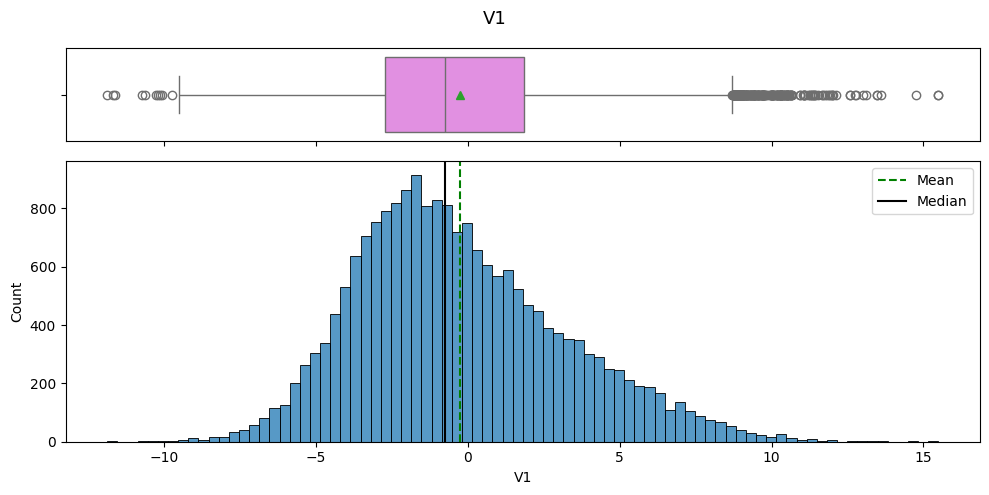

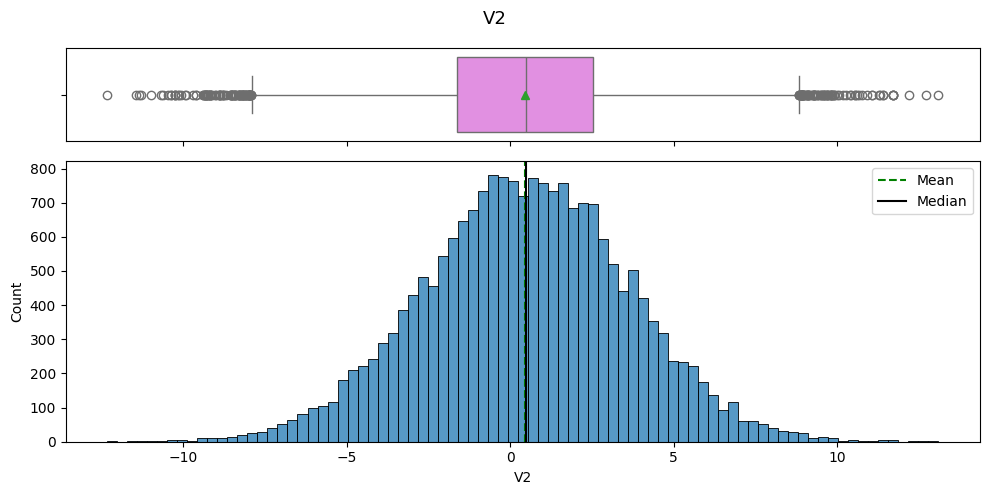

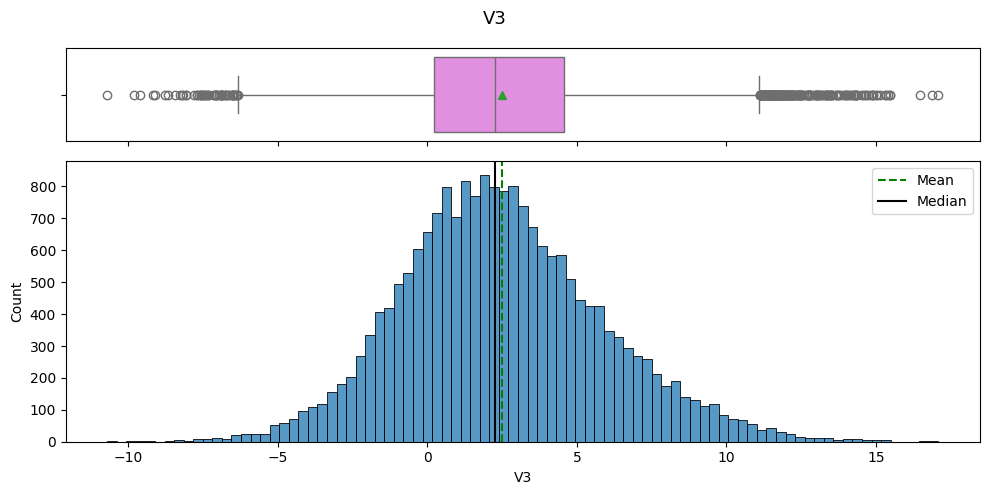

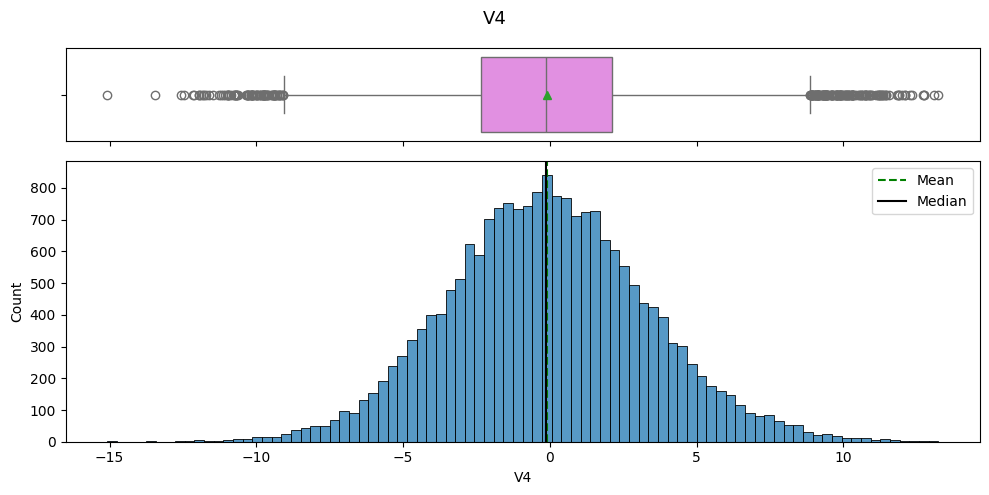

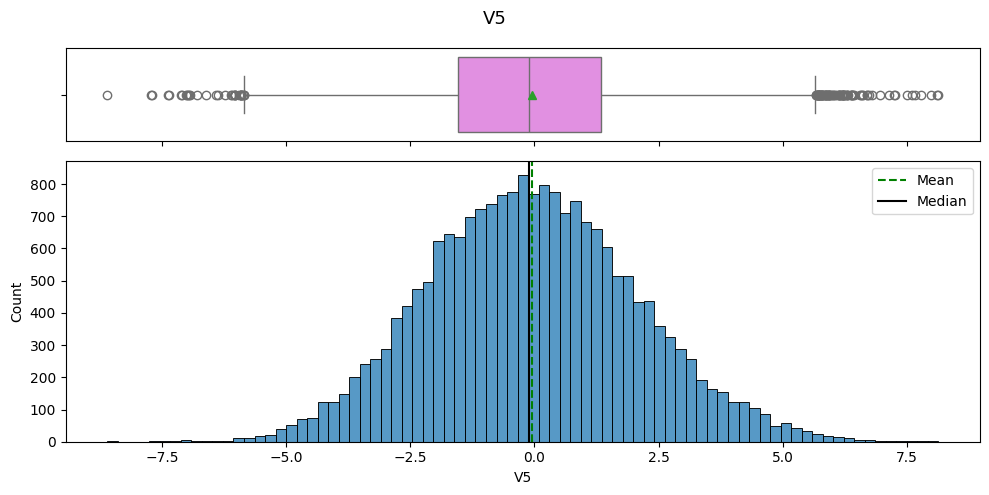

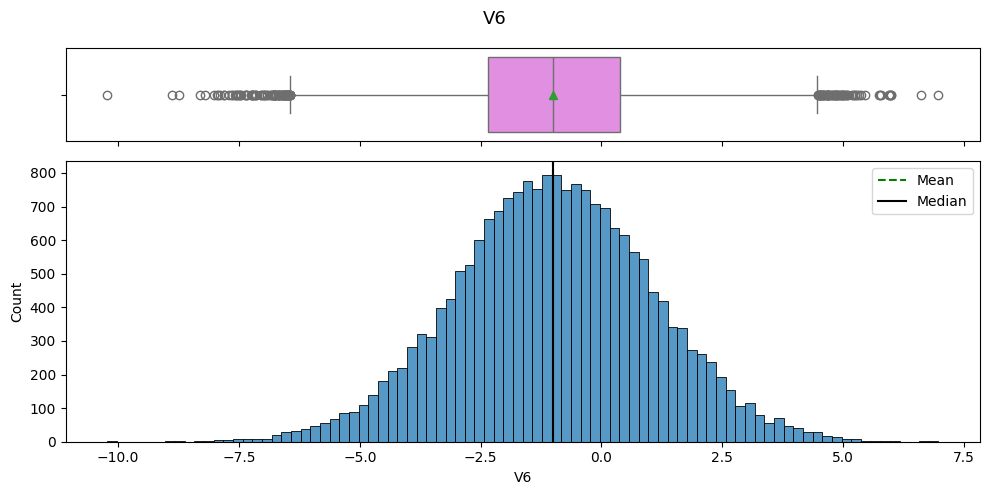

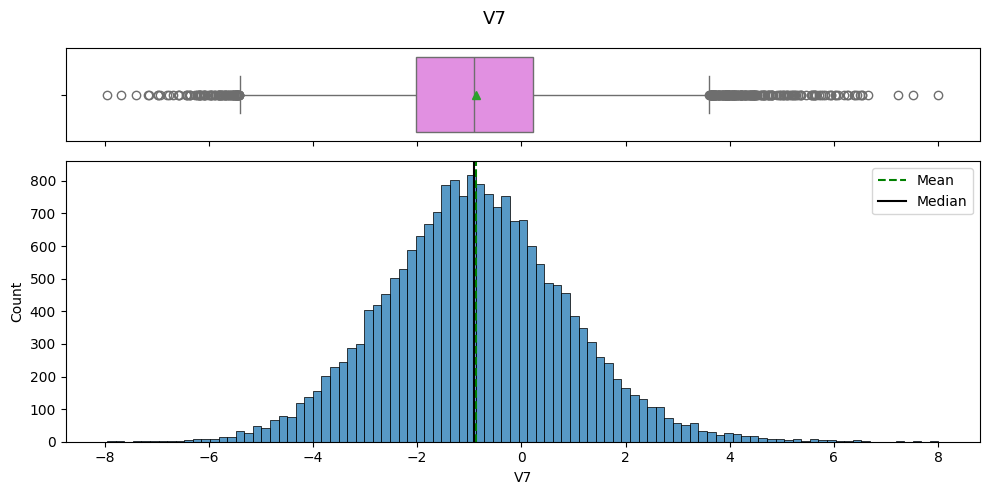

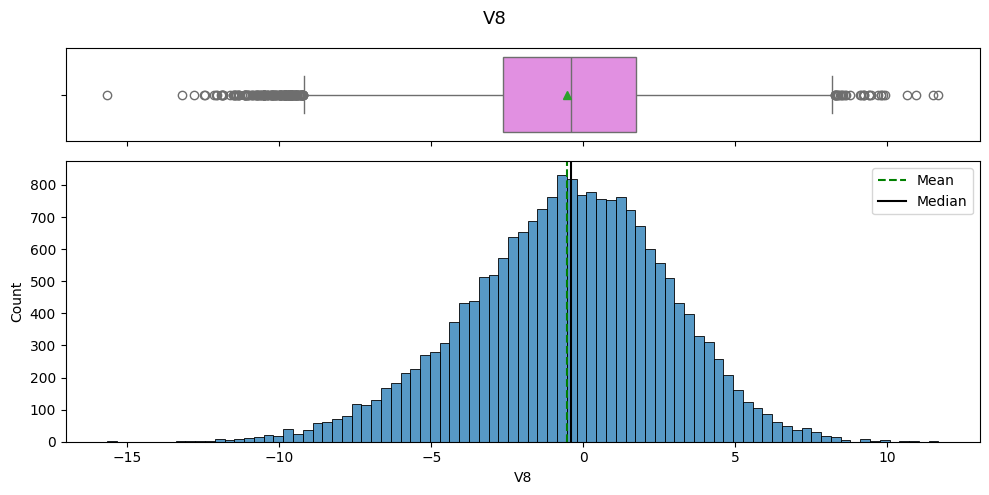

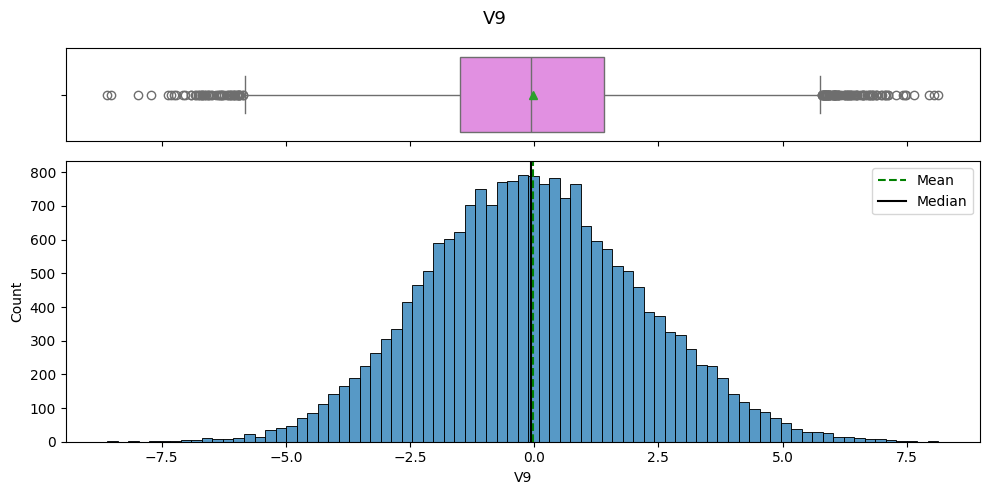

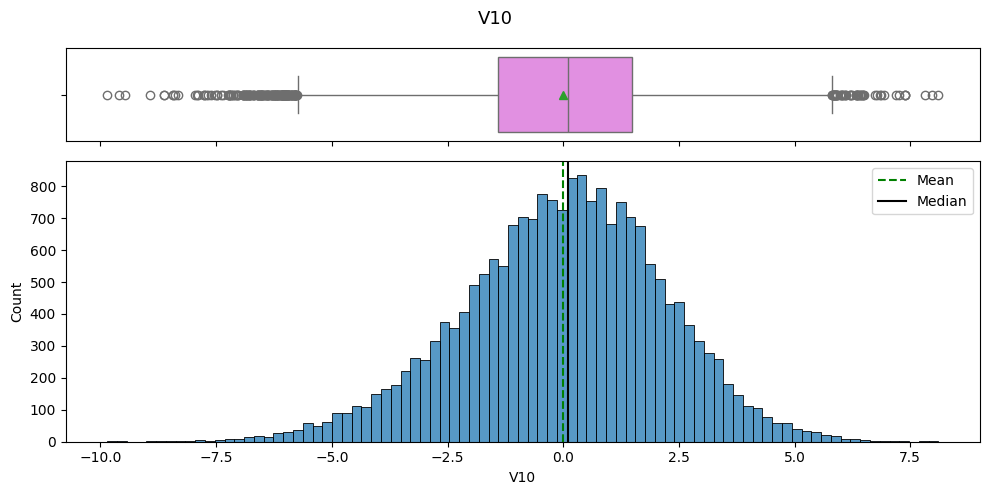

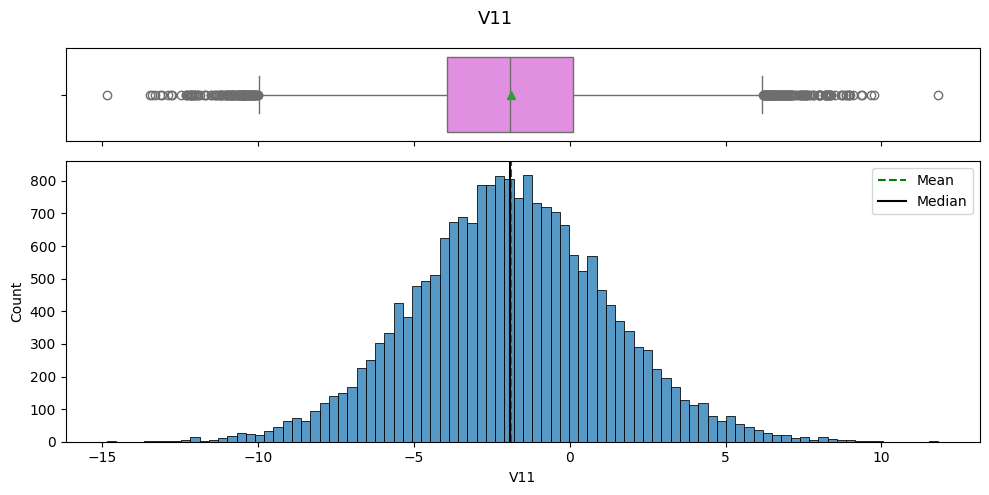

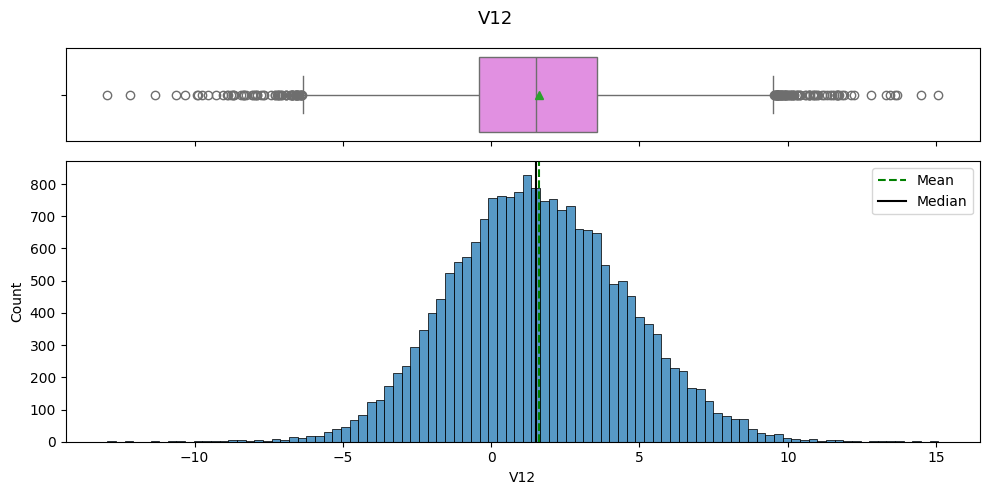

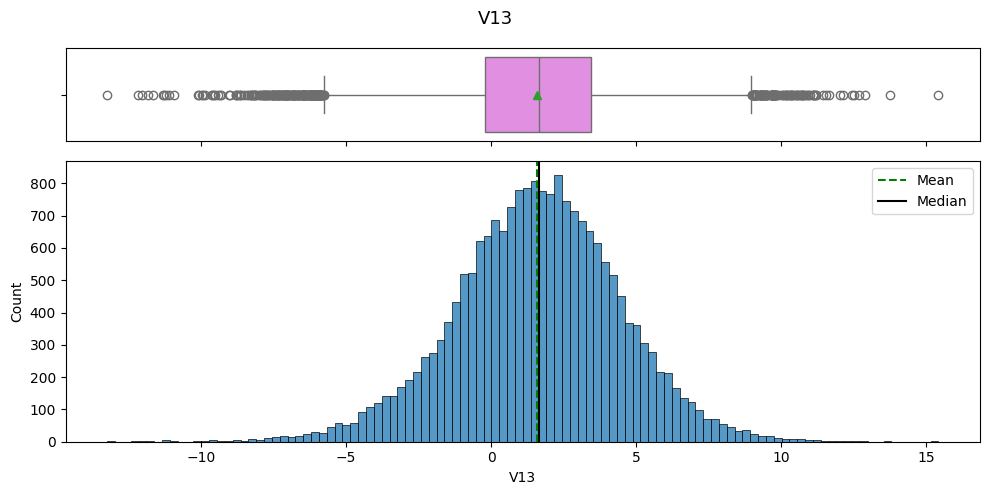

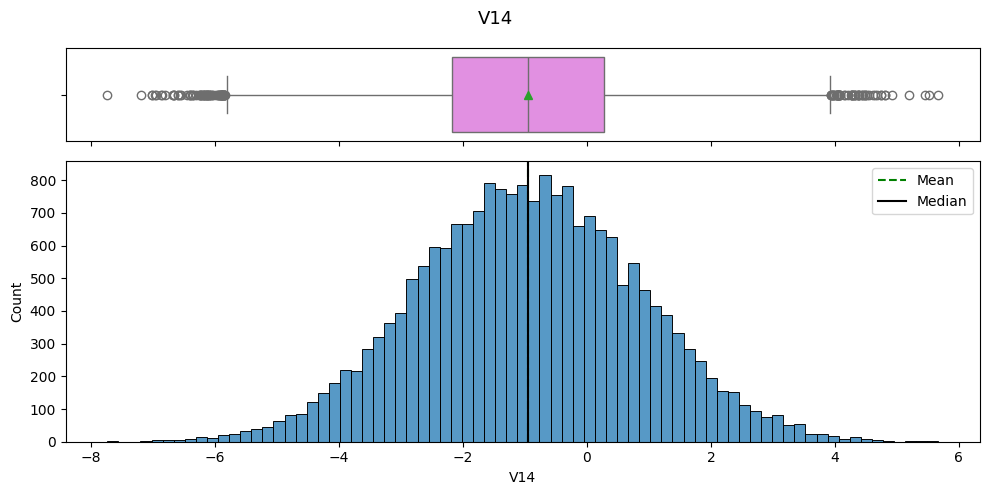

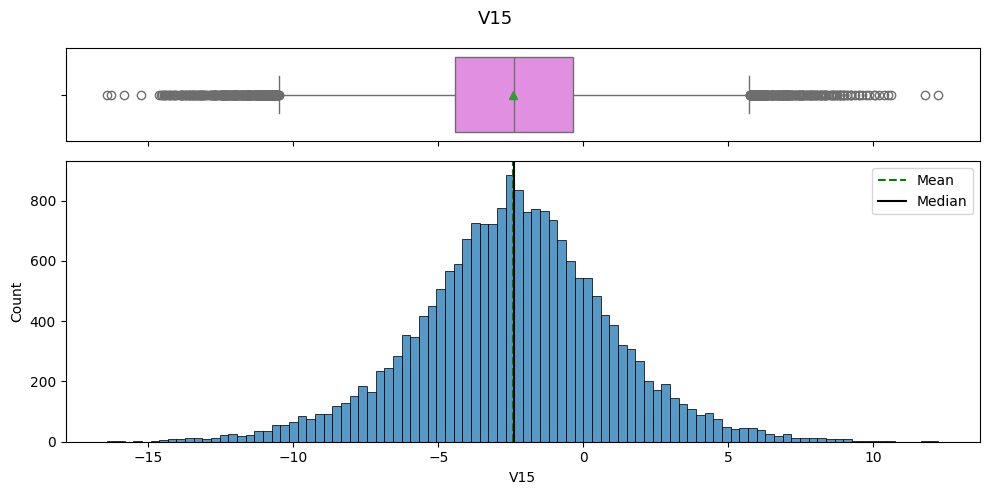

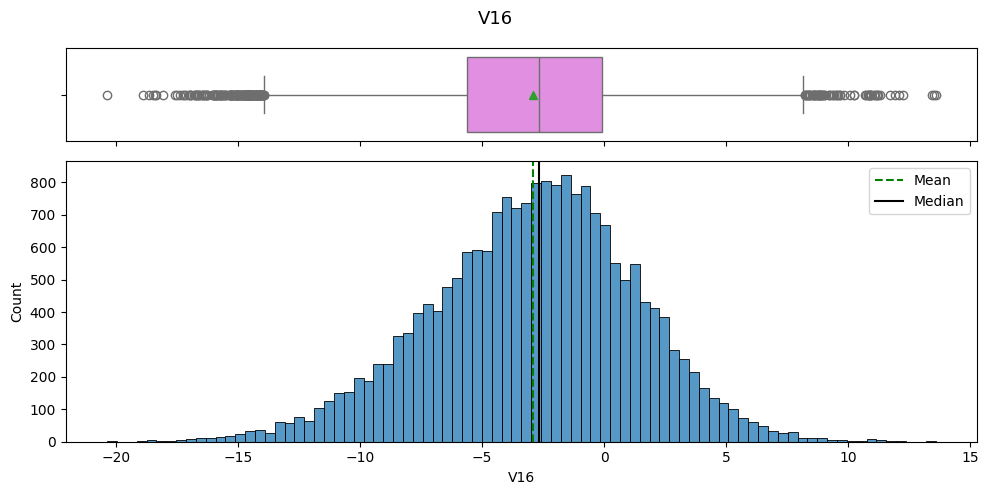

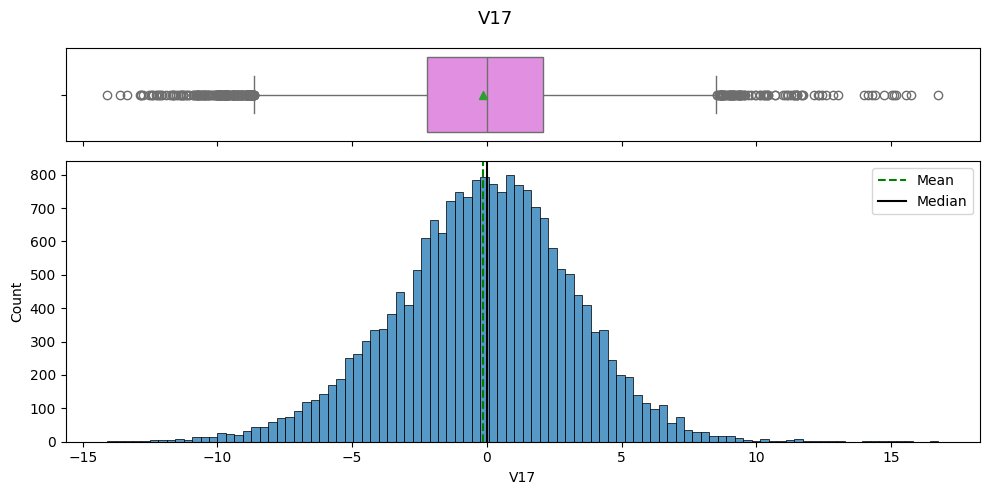

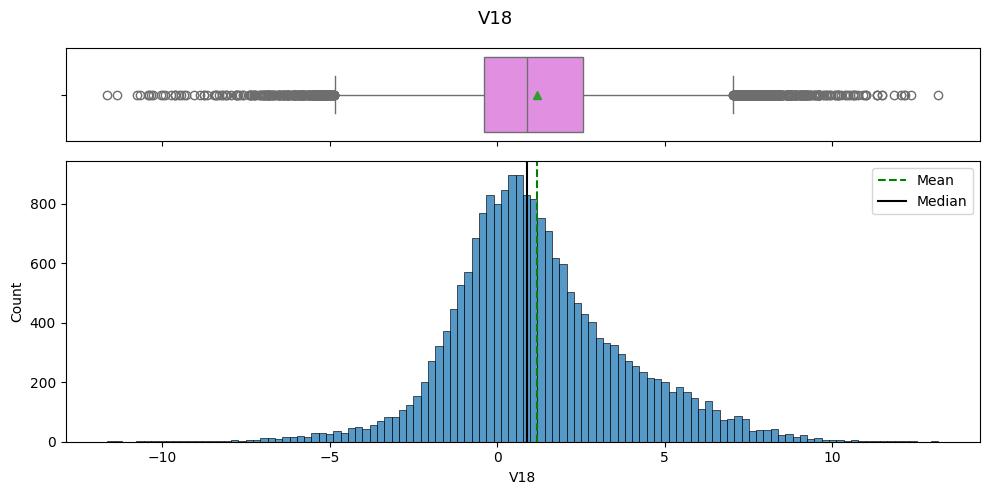

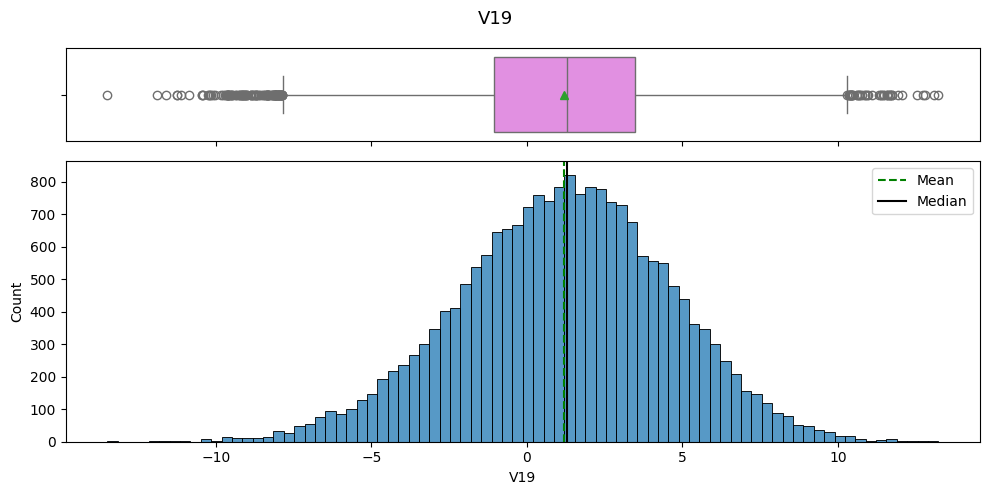

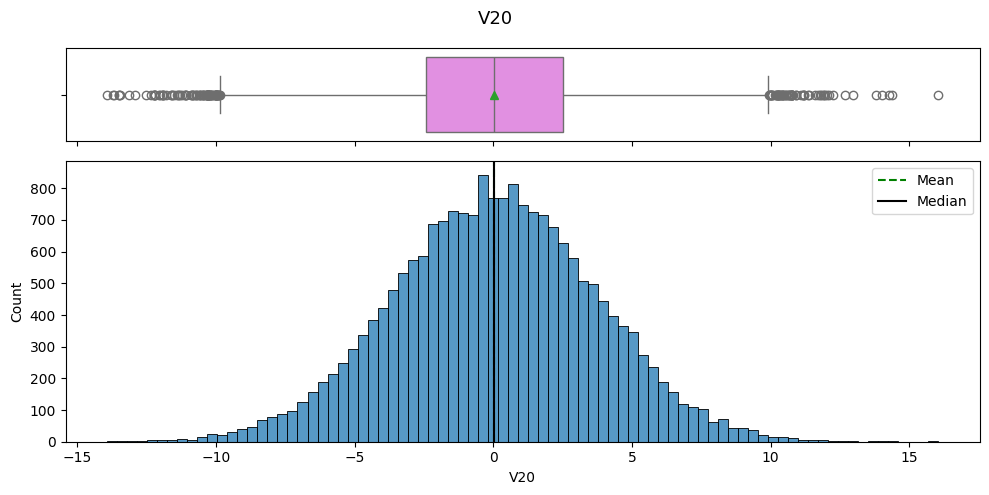

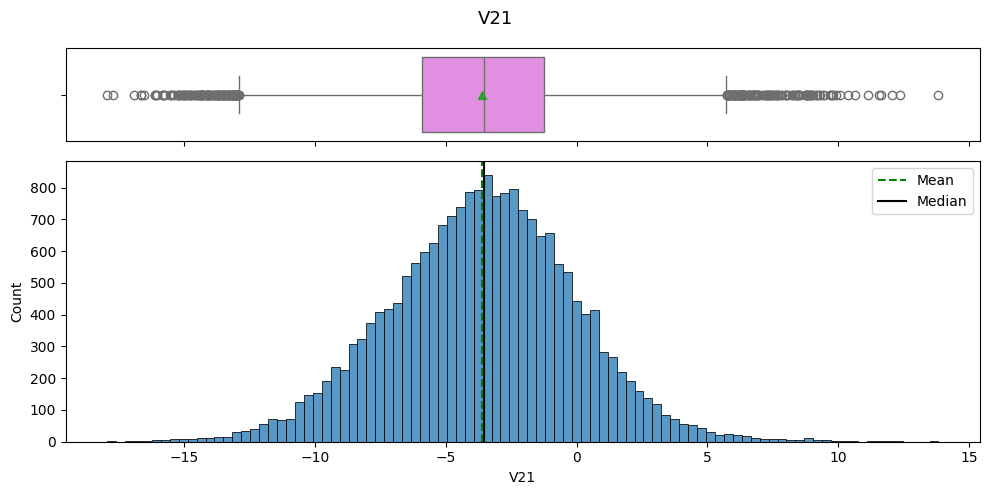

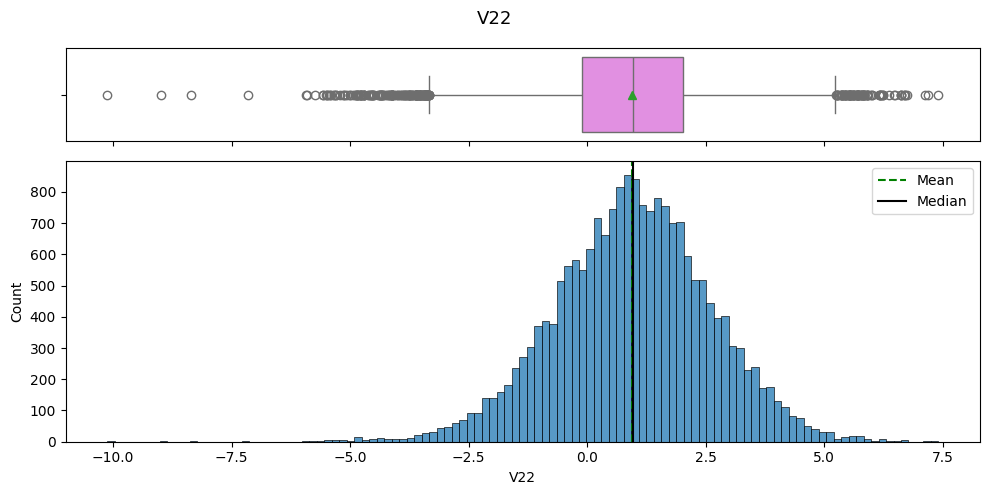

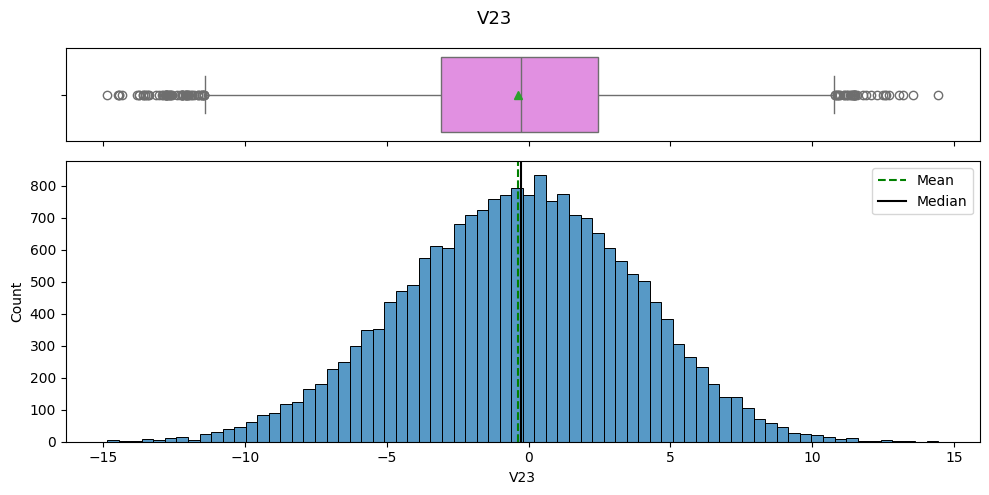

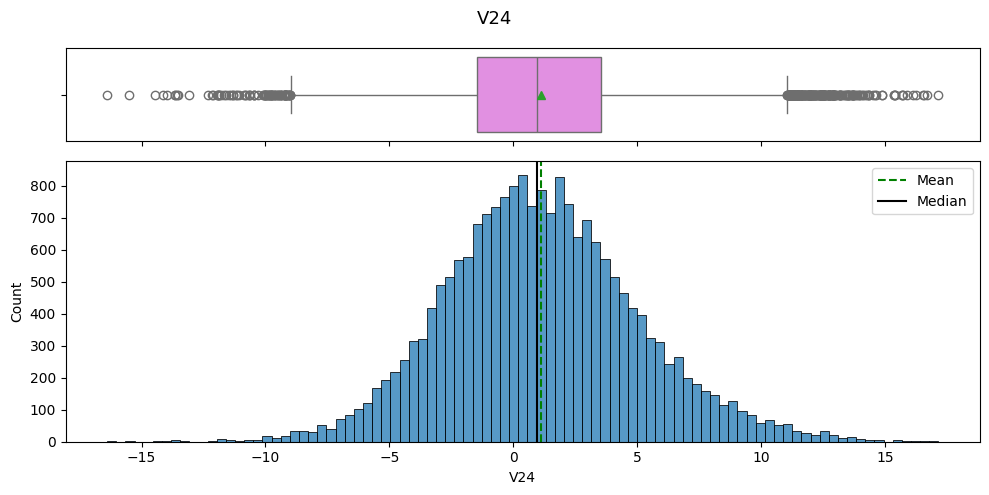

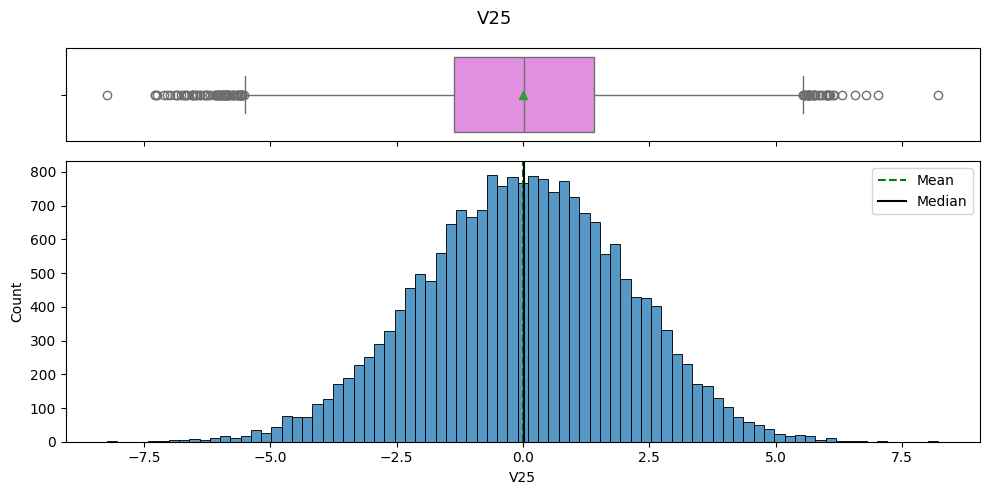

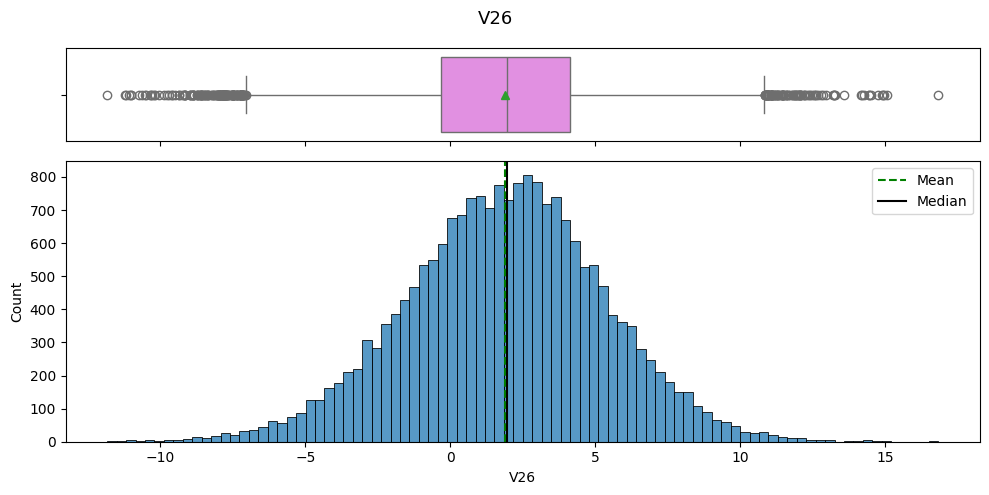

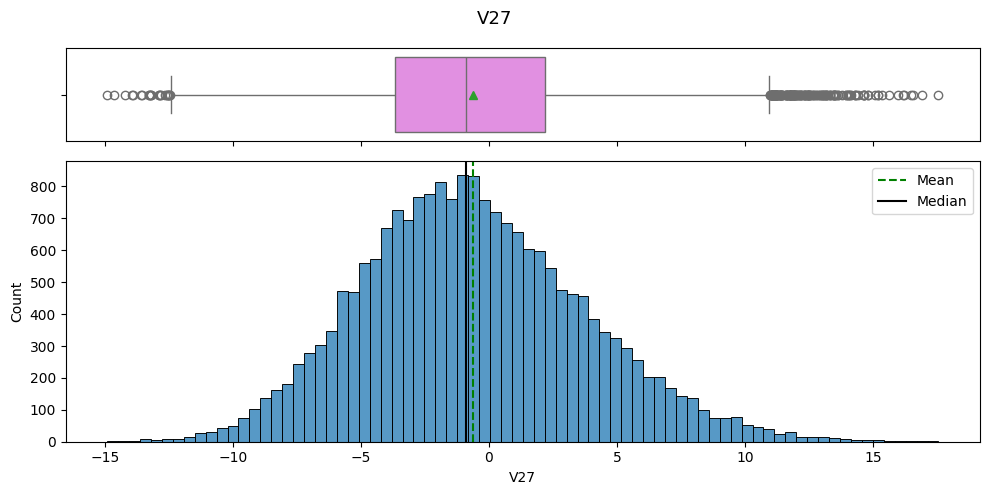

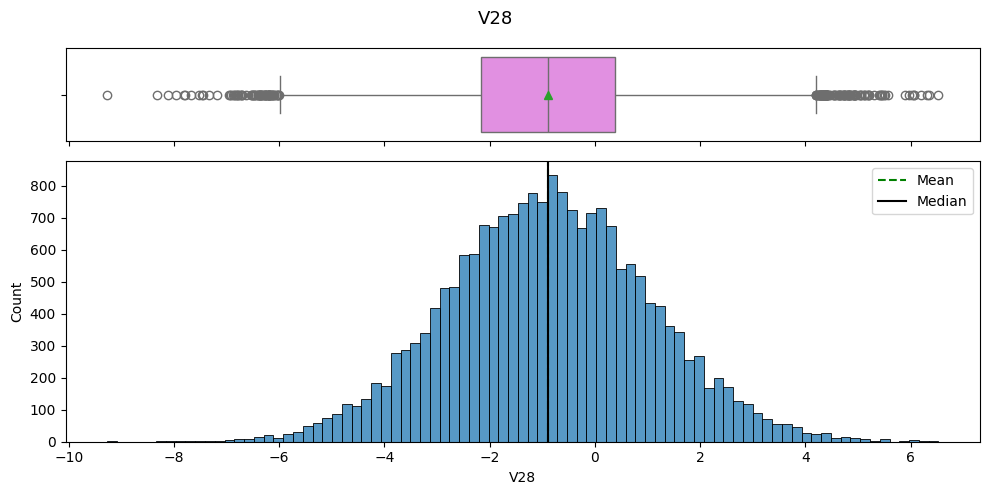

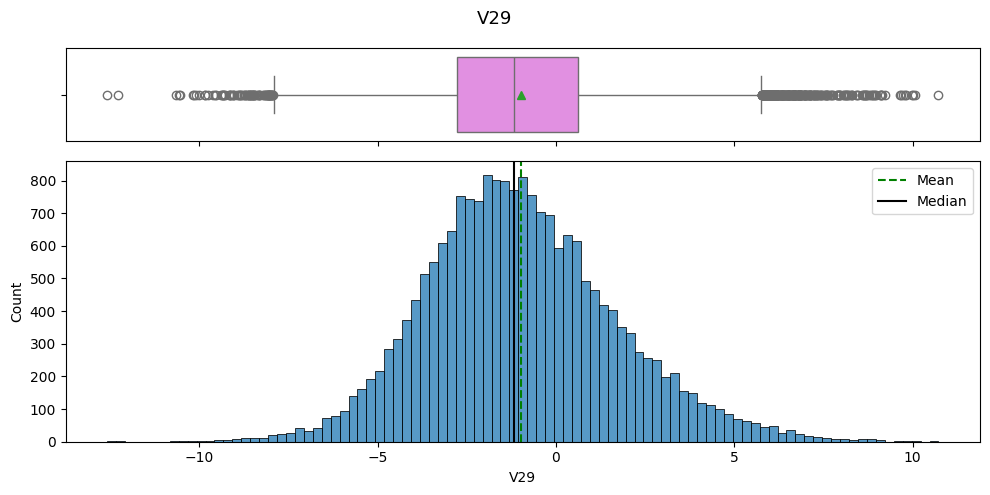

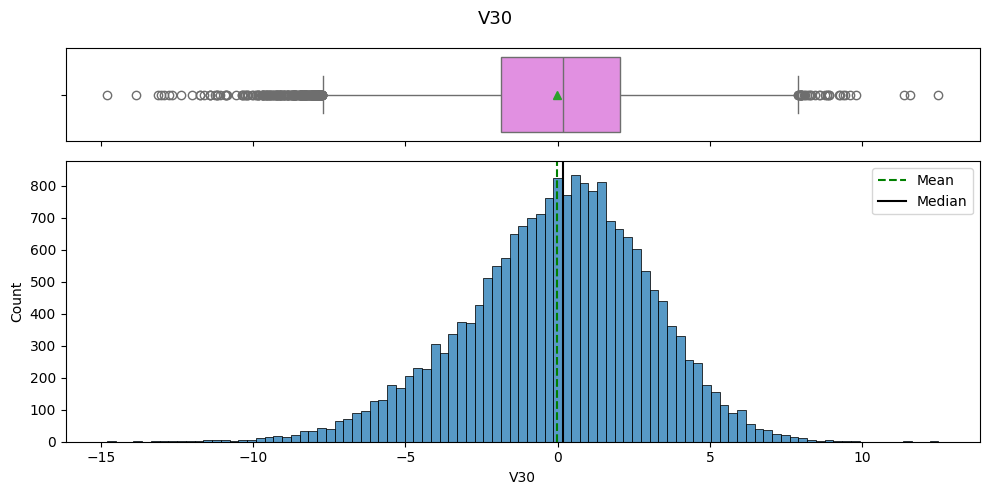

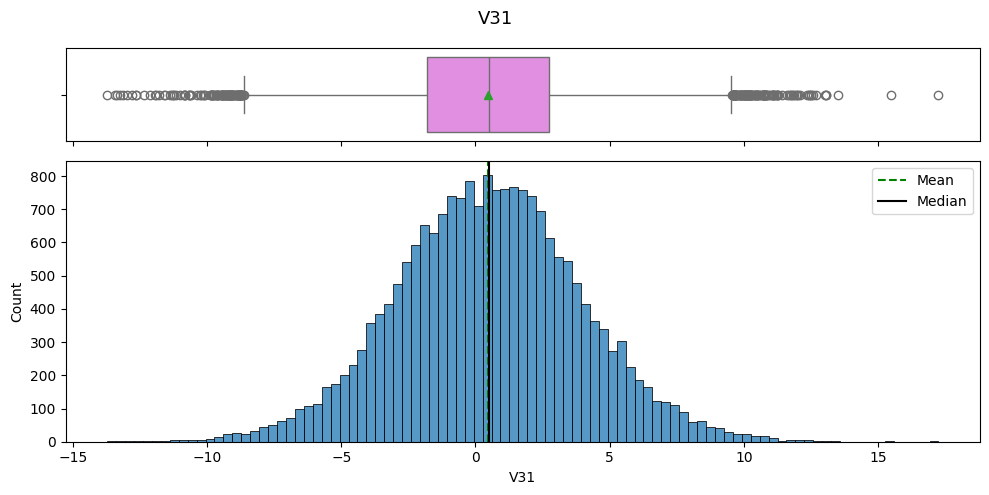

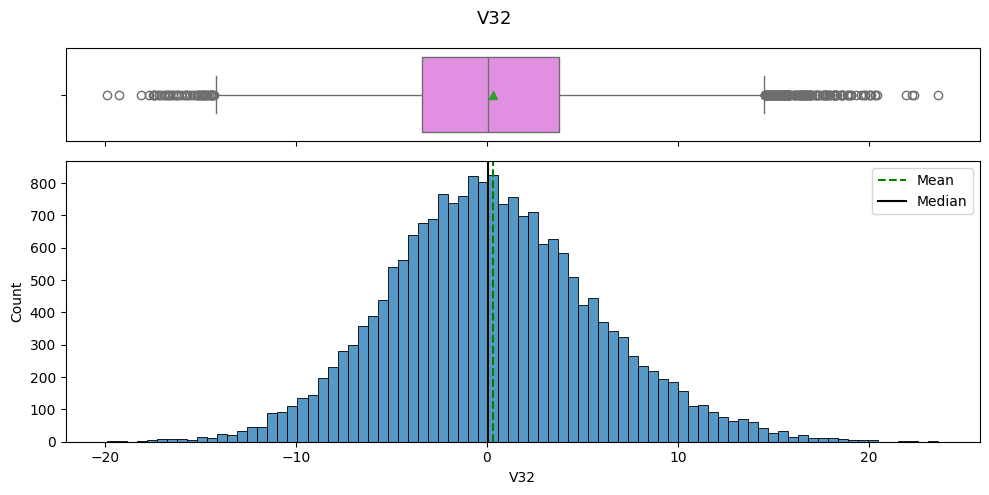

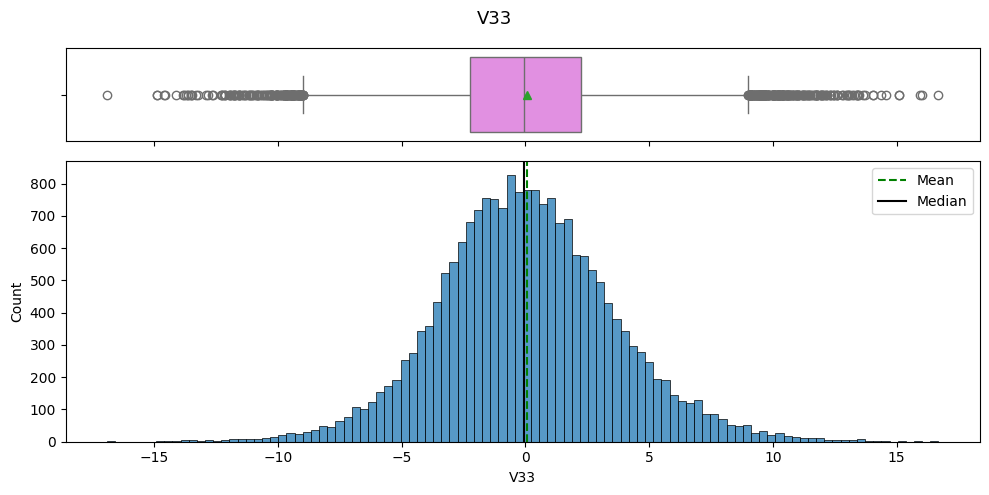

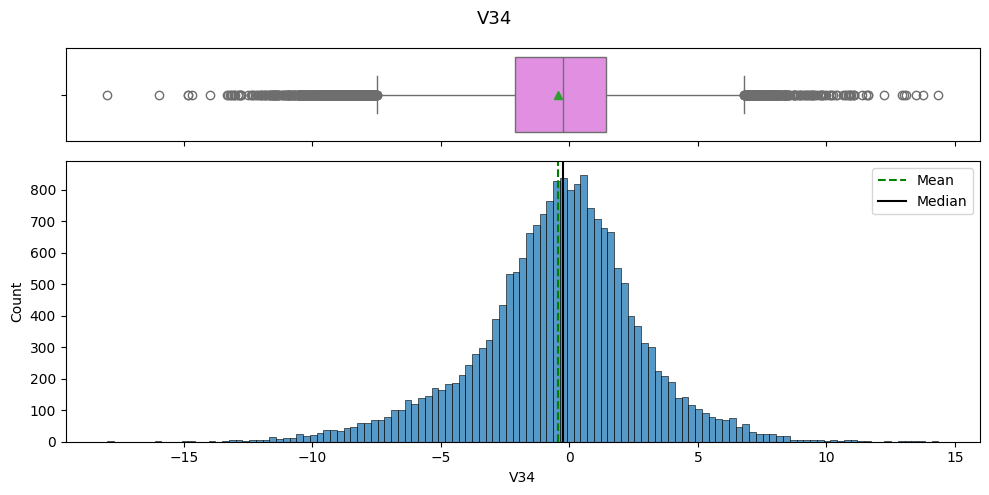

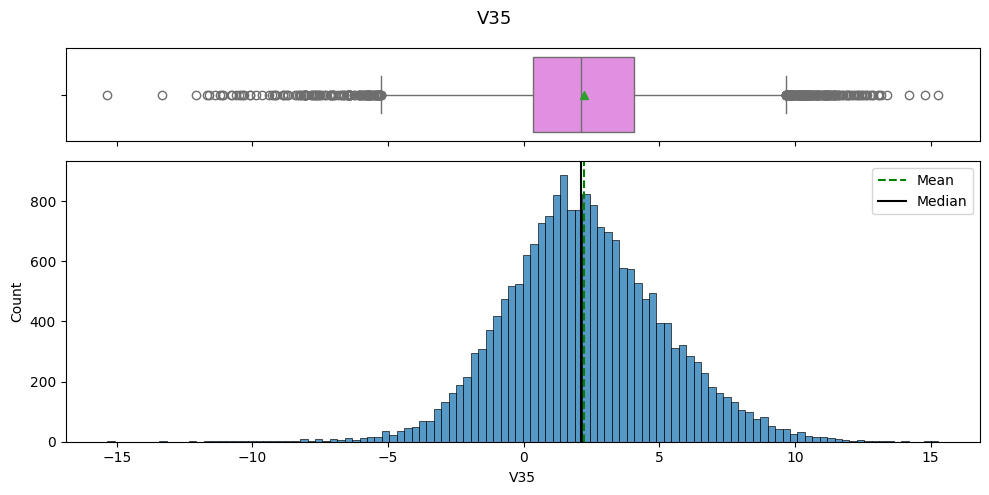

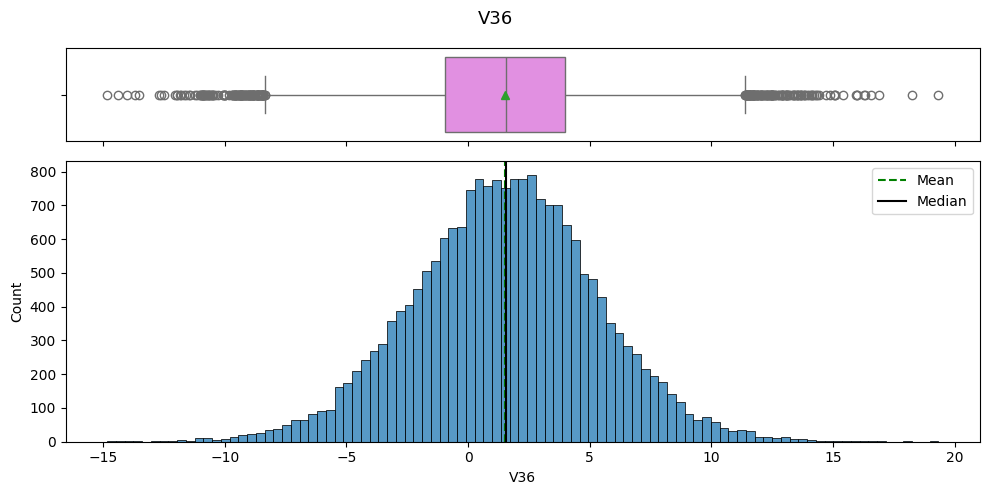

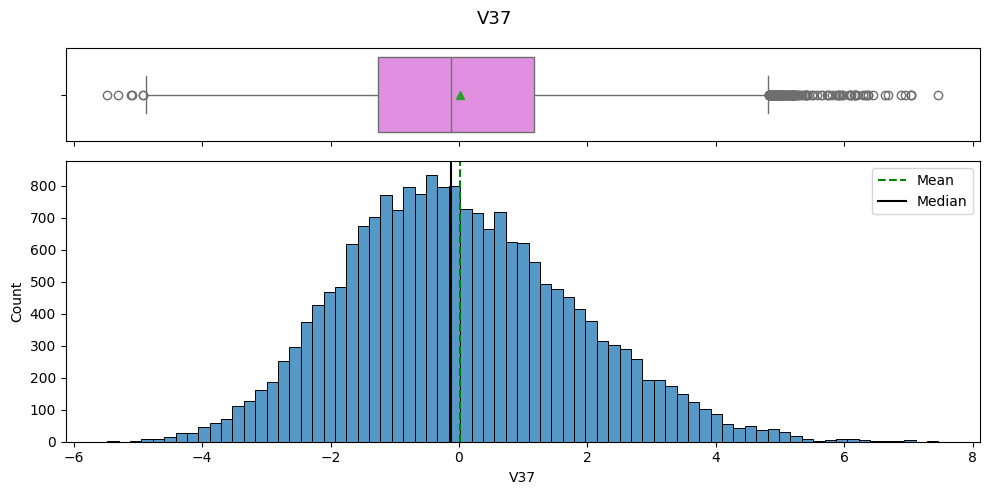

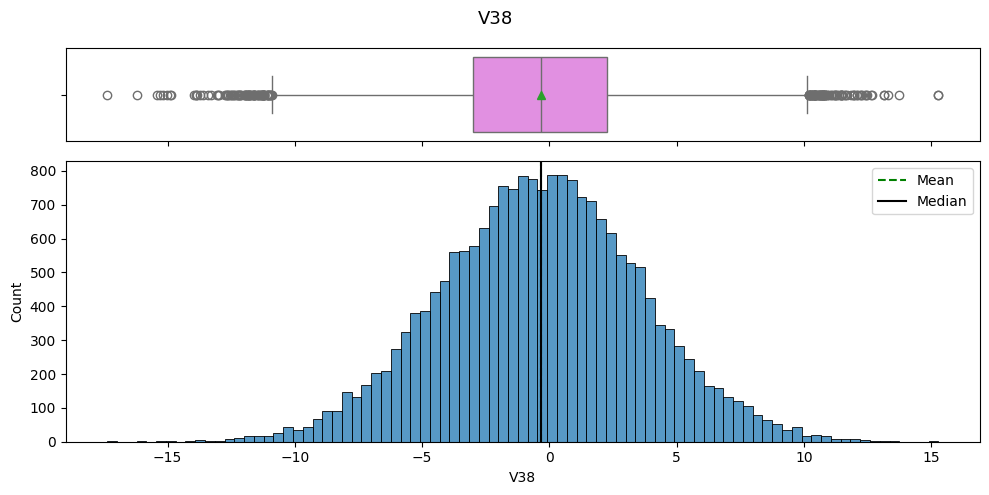

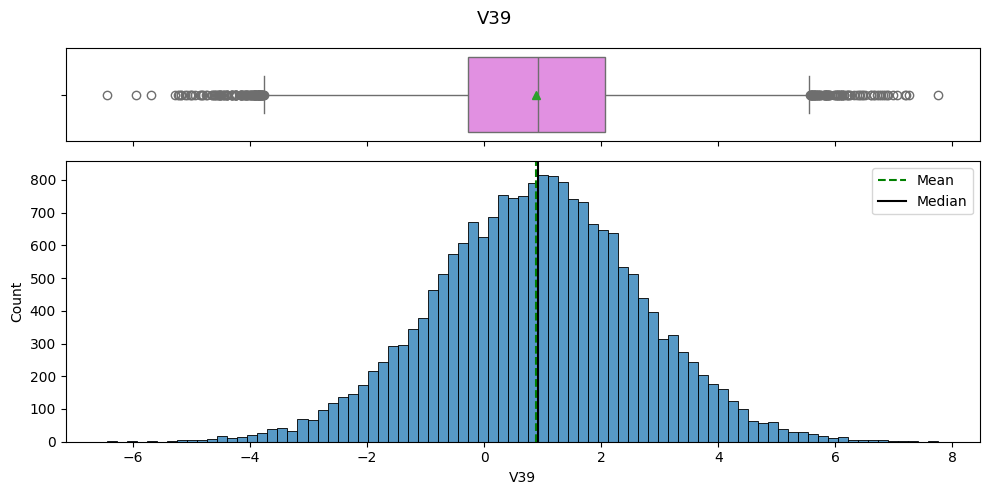

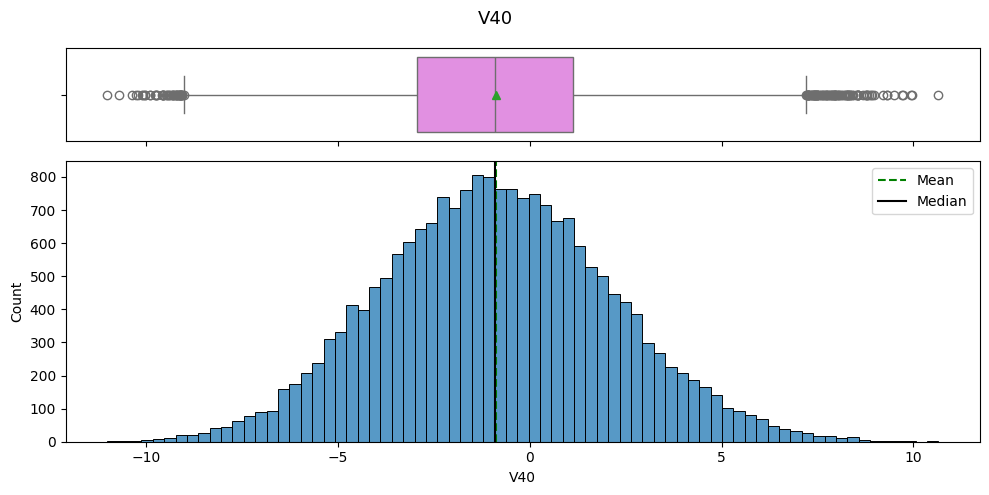

In [107]:
# Plot boxplot + histogram for every predictor feature
for feature in [c for c in df.columns if c != 'Target']:
    histogram_boxplot(df, feature, figsize=(10, 5))


### Checking the distribution of the Target variable

In [108]:
# Class proportions – training data
print("Target proportions (train):")
print(df['Target'].value_counts(normalize=True).round(4) * 100)


Target proportions (train):
Target
0    94.45
1     5.55
Name: proportion, dtype: float64


In [109]:
# Class proportions – test data
print("Target proportions (test):")
print(df_test['Target'].value_counts(normalize=True).round(4) * 100)


Target proportions (test):
Target
0    94.36
1     5.64
Name: proportion, dtype: float64


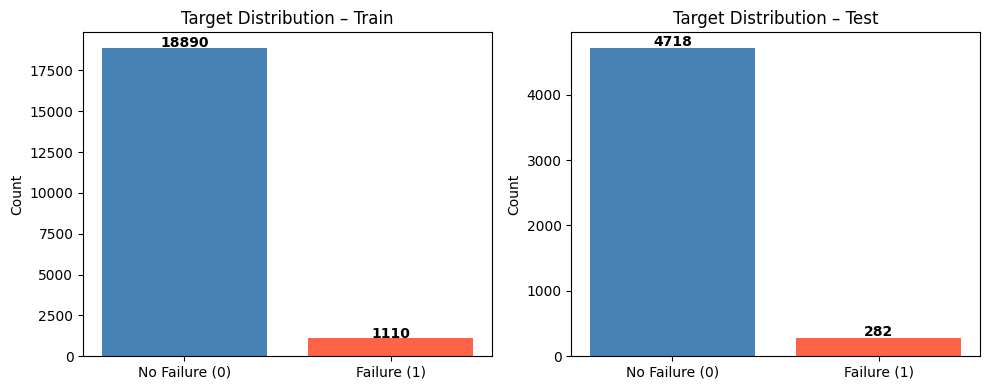

In [110]:
# Bar chart of class balance
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (dframe, title) in zip(axes, [(df, 'Train'), (df_test, 'Test')]):
    counts = dframe['Target'].value_counts()
    ax.bar(['No Failure (0)', 'Failure (1)'], counts.values,
           color=['steelblue', 'tomato'])
    ax.set_title(f'Target Distribution – {title}')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 30, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


**Observation:** The target is strongly imbalanced in both train and test sets (~94.5 % no-failure). Without corrective measures the model would simply predict "no failure" every time and appear very accurate while missing all real failures.


### 4b. Bivariate Analysis – Correlation Check

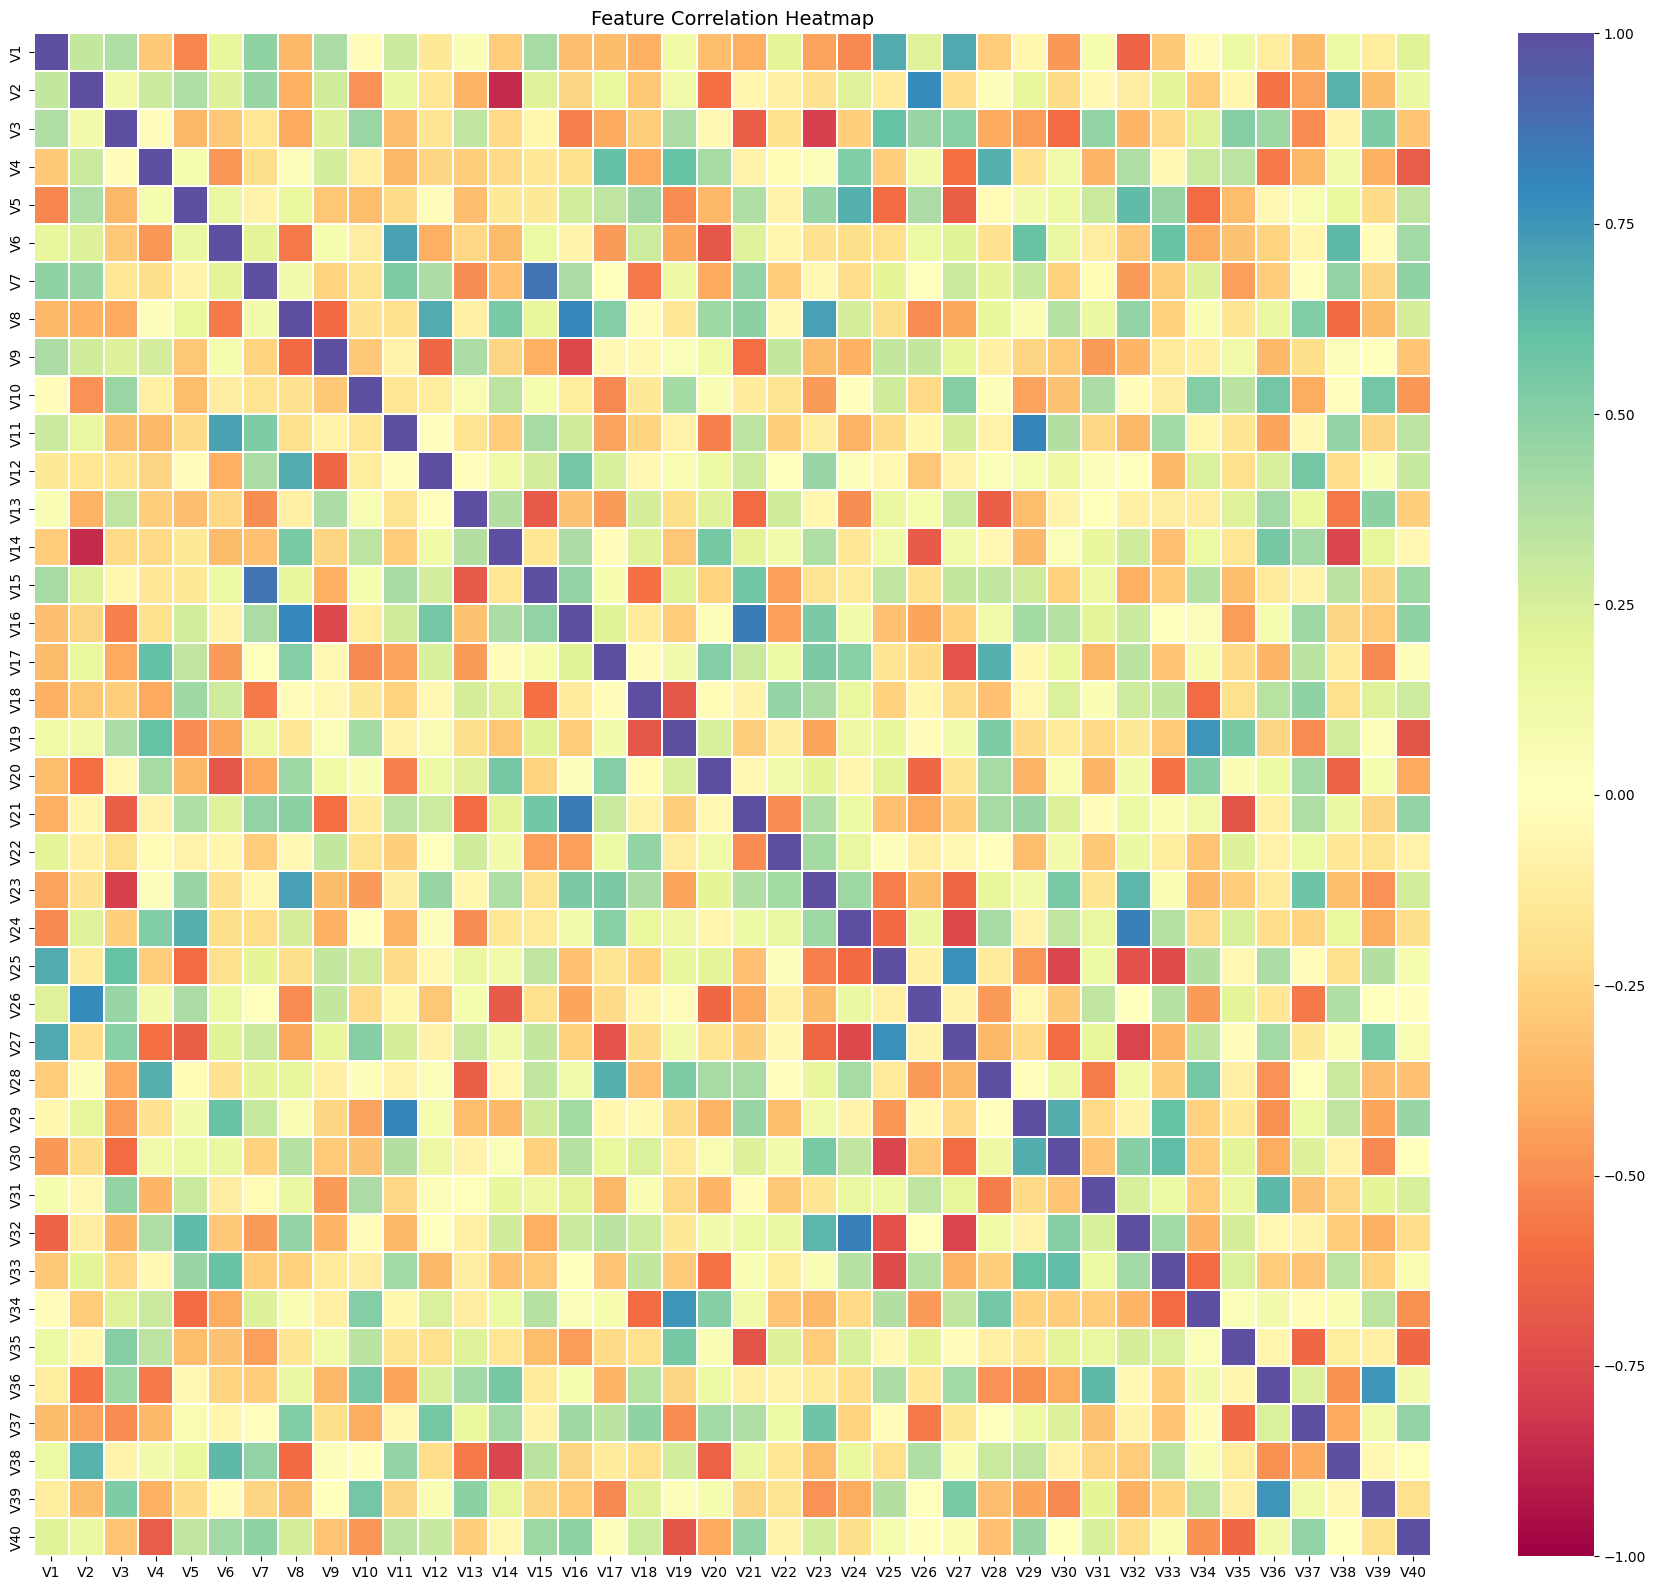

In [111]:
cols_list = df.select_dtypes(include=np.number).columns.tolist()
cols_list.remove("Target")

plt.figure(figsize=(18, 16))
sns.heatmap(
    df[cols_list].corr(), annot=False, vmin=-1, vmax=1,
    fmt=".2f", cmap="Spectral", linewidths=0.3
)
plt.title("Feature Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()


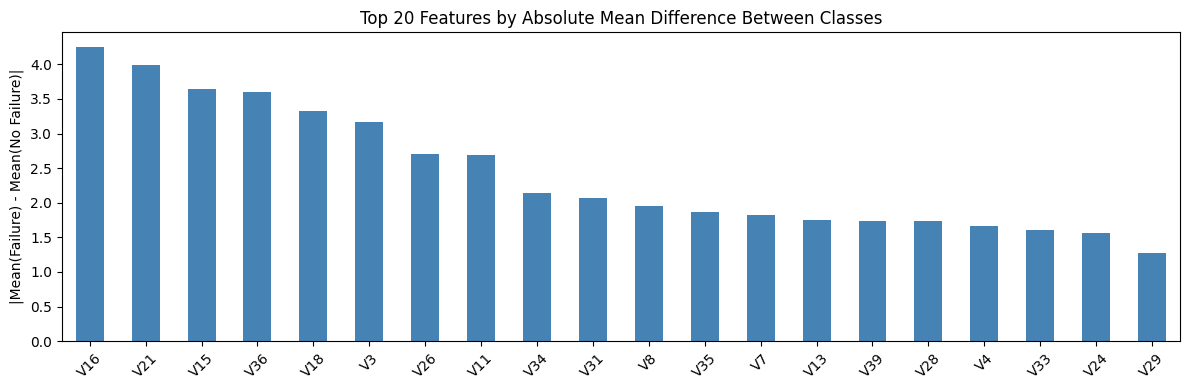

In [112]:
# Mean feature values by class – shows which features differ most between classes
mean_by_class = df.groupby('Target')[cols_list].mean()
diff = (mean_by_class.loc[1] - mean_by_class.loc[0]).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 4))
diff.head(20).plot(kind='bar', color='steelblue')
plt.title('Top 20 Features by Absolute Mean Difference Between Classes')
plt.ylabel('|Mean(Failure) - Mean(No Failure)|')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observations:**
- The correlation heatmap shows no extreme multicollinearity among features.
- Several features show meaningfully different mean values between failure and no-failure classes, indicating predictive signal.


## 5. Data Preprocessing

### Splitting features and target

In [113]:
# Separate predictors (X) and target (y) for train and test
X      = data.drop(columns=["Target"], axis=1)
y      = data["Target"]

X_test = data_test.drop(columns=["Target"], axis=1)
y_test = data_test["Target"]

print("X shape     :", X.shape)
print("X_test shape:", X_test.shape)


X shape     : (20000, 40)
X_test shape: (5000, 40)


Since we already have a separate test set, we only need to split the training data into train and validation sets.

In [114]:
# 80% train / 20% validation – stratify preserves class ratio in both sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)


X_train shape: (16000, 40)
X_val shape  : (4000, 40)
X_test shape : (5000, 40)


### Missing Value Imputation

- V1 and V2 have a small number of missing values; we impute them with the **median**.
- We fit the imputer **only on training data** and then transform validation and test sets — this prevents data leakage.


In [115]:
imputer = SimpleImputer(strategy="median")

# Fit on train, transform all three sets
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_val   = pd.DataFrame(imputer.transform(X_val),   columns=X_train.columns)
X_test  = pd.DataFrame(imputer.transform(X_test),  columns=X_train.columns)

print("Missing values after imputation:")
print("  X_train:", X_train.isna().sum().sum())
print("  X_val  :", X_val.isna().sum().sum())
print("  X_test :", X_test.isna().sum().sum())


Missing values after imputation:
  X_train: 0
  X_val  : 0
  X_test : 0


### Feature Scaling

In [116]:
# StandardScaler: fit on train only, then transform val and test
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print("Scaling complete.")
print("Train mean (should be ~0):", X_train.mean().round(4))
print("Train std  (should be ~1):", X_train.std().round(4))


Scaling complete.
Train mean (should be ~0): 0.0
Train std  (should be ~1): 1.0


In [117]:
# Convert target arrays to numpy (required by Keras)
y_train = y_train.to_numpy()
y_val   = y_val.to_numpy()
y_test  = y_test.to_numpy()

print("y_train shape:", y_train.shape, "| dtype:", y_train.dtype)


y_train shape: (16000,) | dtype: float64


## 6. Model Building

### Model Evaluation Criterion

**Primary metric: Recall**

Given the cost structure:
- False Negatives (missed failures) → most expensive outcome (full replacement)
- False Positives (false alarms)    → cheapest outcome (just an inspection)

Recall = TP / (TP + FN) directly measures how many real failures we catch. Maximising recall minimises the most costly error. We also track Accuracy, Precision and F1 to ensure the model remains practically useful.


### Utility Functions

In [118]:
# ── Plot training curves ────────────────────────────────────────────────────
def plot(history, name):
    """
    Plot training vs validation loss or a chosen metric.
    name: 'loss', 'accuracy', 'recall', etc.
    """
    fig, ax = plt.subplots()
    plt.plot(history.history[name])
    plt.plot(history.history['val_' + name])
    plt.title('Model ' + name.capitalize())
    plt.ylabel(name.capitalize())
    plt.xlabel('Epoch')
    fig.legend(['Train', 'Validation'], loc="upper right")
    plt.tight_layout()
    plt.show()


# ── Compute performance metrics and return a DataFrame ─────────────────────
def model_performance_classification(model, predictors, target, threshold=0.5):
    """
    Returns Accuracy, Recall, Precision and F1 as a single-row DataFrame.
    Works with threshold=0.5 by default (can be adjusted).
    """
    pred = model.predict(predictors, verbose=0) > threshold

    acc       = accuracy_score(target, pred)
    recall    = recall_score(target, pred, average='macro')
    precision = precision_score(target, pred, average='macro')
    f1        = f1_score(target, pred, average='macro')

    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1},
        index=[0]
    )
    return df_perf


print("Utility functions ready.")


Utility functions ready.


### Shared training settings

In [119]:
# Fixed epochs and batch size used consistently across all models
# so comparisons are fair (no early stopping)
epochs     = 50
batch_size = 64

print(f"Epochs: {epochs} | Batch size: {batch_size}")


Epochs: 50 | Batch size: 64


### Model 0 – Baseline (1 hidden layer, SGD)

Starting point:
- 1 hidden layer with **7 neurons**
- ReLU activation
- SGD optimiser


In [120]:
tf.keras.backend.clear_session()   # frees memory from any previous models

model_0 = Sequential()
model_0.add(Dense(7, activation='relu', input_dim=X_train.shape[1]))
model_0.add(Dense(1, activation='sigmoid'))

model_0.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 7)              │           287 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295 (1.15 KB)

 Trainable params: 295 (1.15 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
optimizer = tf.keras.optimizers.SGD()
model_0.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [122]:
start = time.time()
history_0 = model_0.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 35.1 seconds


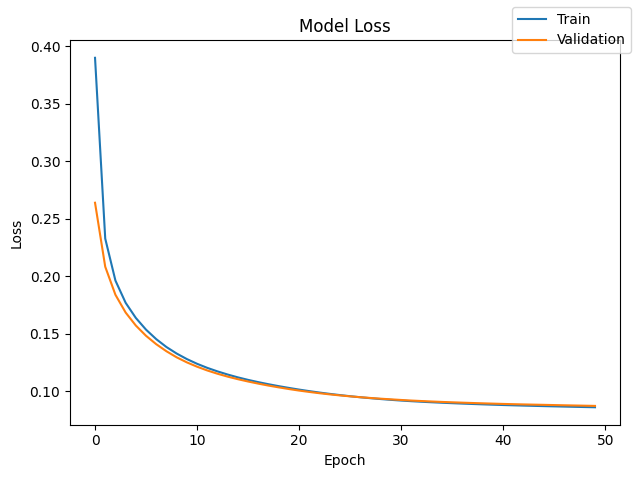

In [123]:
plot(history_0, 'loss')


In [124]:
model_0_train_perf = model_performance_classification(model_0, X_train, y_train)
model_0_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.978,0.817171,0.965106,0.875474


In [125]:
model_0_val_perf = model_performance_classification(model_0, X_val, y_val)
model_0_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.979,0.82989,0.961398,0.883379


In [126]:
y_train_pred_0 = model_0.predict(X_train, verbose=0)
y_val_pred_0   = model_0.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 0)\n")
print(classification_report(y_train, y_train_pred_0 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 0)\n")
print(classification_report(y_val, y_val_pred_0 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 0)

              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99     15112
     Failure       0.95      0.64      0.76       888

    accuracy                           0.98     16000
   macro avg       0.97      0.82      0.88     16000
weighted avg       0.98      0.98      0.98     16000

Classification Report – Validation  (Model 0)

              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      3778
     Failure       0.94      0.66      0.78       222

    accuracy                           0.98      4000
   macro avg       0.96      0.83      0.88      4000
weighted avg       0.98      0.98      0.98      4000



**Model 0 Observations:**
- This is our baseline. With only 7 neurons and SGD the model has very limited capacity.
- Recall on the minority class (failure) is likely low here, which is expected from a simple baseline without class imbalance handling.


### Model 1 – More Hidden Layers (SGD)

Adding a second hidden layer to give the model more capacity to learn non-linear patterns.


In [127]:
tf.keras.backend.clear_session()

model_1 = Sequential()
model_1.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model_1.add(Dense(32, activation='relu'))
model_1.add(Dense(1,  activation='sigmoid'))

model_1.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [128]:
optimizer = tf.keras.optimizers.SGD()
model_1.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [129]:
start = time.time()
history_1 = model_1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 37.0 seconds


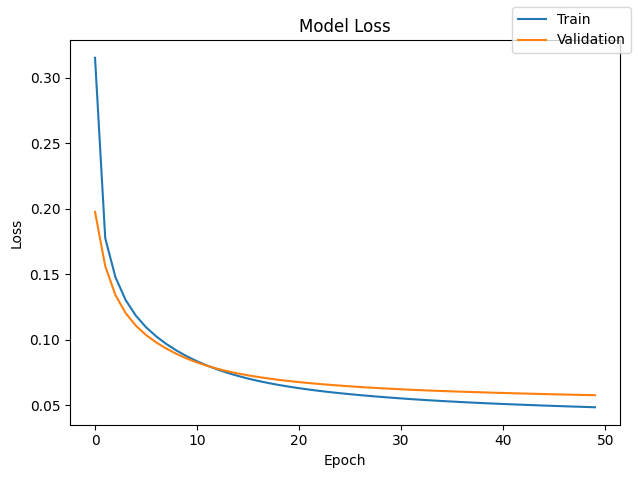

In [130]:
plot(history_1, 'loss')


In [131]:
model_1_train_perf = model_performance_classification(model_1, X_train, y_train)
model_1_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.990187,0.916369,0.98914,0.949461


In [132]:
model_1_val_perf = model_performance_classification(model_1, X_val, y_val)
model_1_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.98825,0.904744,0.980982,0.939165


In [133]:
y_train_pred_1 = model_1.predict(X_train, verbose=0)
y_val_pred_1   = model_1.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 1)\n")
print(classification_report(y_train, y_train_pred_1 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 1)\n")
print(classification_report(y_val, y_val_pred_1 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 1)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99     15112
     Failure       0.99      0.83      0.90       888

    accuracy                           0.99     16000
   macro avg       0.99      0.92      0.95     16000
weighted avg       0.99      0.99      0.99     16000

Classification Report – Validation  (Model 1)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      3778
     Failure       0.97      0.81      0.88       222

    accuracy                           0.99      4000
   macro avg       0.98      0.90      0.94      4000
weighted avg       0.99      0.99      0.99      4000



**Model 1 Observations:**
- More capacity from the additional hidden layer should improve the model's ability to learn complex patterns compared to the single-layer baseline.
- Compare train vs validation recall to check for overfitting.


### Model 2 – Dropout Regularisation (SGD)

Adding a Dropout layer (50 %) after the first hidden layer to reduce overfitting.
Dropout randomly turns off neurons during each training step, forcing the network to learn more robust features.


In [134]:
tf.keras.backend.clear_session()

model_2 = Sequential()
model_2.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model_2.add(Dropout(0.5))    # drop 50% of neurons randomly during training
model_2.add(Dense(32, activation='relu'))
model_2.add(Dense(16, activation='relu'))
model_2.add(Dense(1,  activation='sigmoid'))

model_2.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,249 (20.50 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 0 (0.00 B)

In [135]:
optimizer = tf.keras.optimizers.SGD()
model_2.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [136]:
start = time.time()
history_2 = model_2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 40.3 seconds


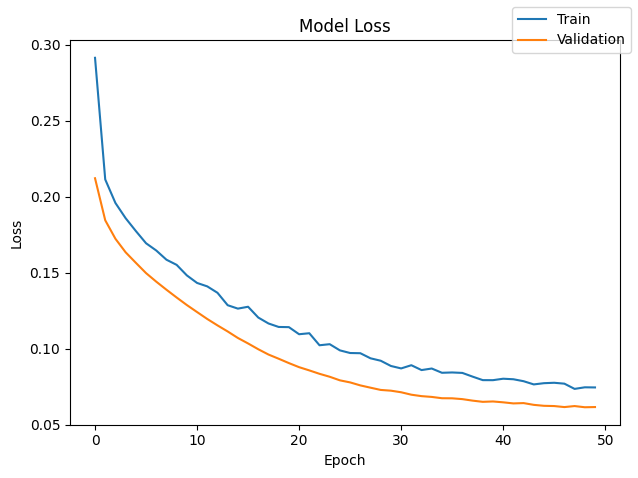

In [137]:
plot(history_2, 'loss')


In [138]:
model_2_train_perf = model_performance_classification(model_2, X_train, y_train)
model_2_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.9855,0.872549,0.988139,0.92164


In [139]:
model_2_val_perf = model_performance_classification(model_2, X_val, y_val)
model_2_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.986,0.880234,0.984356,0.925253


In [140]:
y_train_pred_2 = model_2.predict(X_train, verbose=0)
y_val_pred_2   = model_2.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 2)\n")
print(classification_report(y_train, y_train_pred_2 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 2)\n")
print(classification_report(y_val, y_val_pred_2 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 2)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99     15112
     Failure       0.99      0.75      0.85       888

    accuracy                           0.99     16000
   macro avg       0.99      0.87      0.92     16000
weighted avg       0.99      0.99      0.98     16000

Classification Report – Validation  (Model 2)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      3778
     Failure       0.98      0.76      0.86       222

    accuracy                           0.99      4000
   macro avg       0.98      0.88      0.93      4000
weighted avg       0.99      0.99      0.99      4000



**Model 2 Observations:**
- Dropout should reduce the gap between training and validation performance (less overfitting).
- If validation recall improves over Model 1, the regularisation is helping.


### Model 3 – Class Weights (SGD + Dropout)

We are dealing with a class imbalance (~94.5 % vs 5.5 %). Adding **class weights** tells the model
to penalise mistakes on the minority class (failure) proportionally more, which should improve recall.


In [141]:
# Compute class weights from training labels
cw = y_train.shape[0] / np.bincount(y_train.astype(int))
cw_dict = {i: cw[i] for i in range(len(cw))}
print("Class weights:", cw_dict)
print(f"  → Failure mistakes penalised ~{round(cw[1]/cw[0],1)}x more than no-failure")


Class weights: {0: np.float64(1.0587612493382743), 1: np.float64(18.01801801801802)}
  → Failure mistakes penalised ~17.0x more than no-failure


In [142]:
tf.keras.backend.clear_session()

model_3 = Sequential()
model_3.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model_3.add(Dropout(0.5))
model_3.add(Dense(32, activation='relu'))
model_3.add(Dense(16, activation='relu'))
model_3.add(Dense(1,  activation='sigmoid'))

model_3.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,249 (20.50 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 0 (0.00 B)

In [143]:
optimizer = tf.keras.optimizers.SGD()
model_3.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [144]:
start = time.time()
history_3 = model_3.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    class_weight=cw_dict,    # <-- class weights applied here
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 41.8 seconds


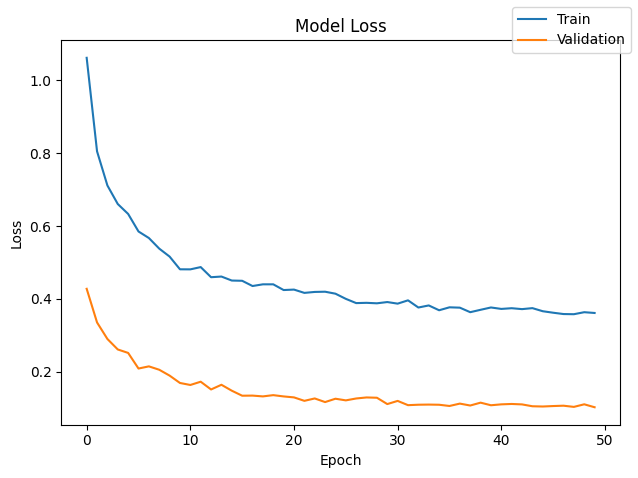

In [145]:
plot(history_3, 'loss')


In [146]:
model_3_train_perf = model_performance_classification(model_3, X_train, y_train)
model_3_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.991875,0.954361,0.967261,0.960708


In [147]:
model_3_val_perf = model_performance_classification(model_3, X_val, y_val)
model_3_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.9905,0.939853,0.967726,0.953304


In [148]:
y_train_pred_3 = model_3.predict(X_train, verbose=0)
y_val_pred_3   = model_3.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 3)\n")
print(classification_report(y_train, y_train_pred_3 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 3)\n")
print(classification_report(y_val, y_val_pred_3 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 3)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00     15112
     Failure       0.94      0.91      0.93       888

    accuracy                           0.99     16000
   macro avg       0.97      0.95      0.96     16000
weighted avg       0.99      0.99      0.99     16000

Classification Report – Validation  (Model 3)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      3778
     Failure       0.94      0.88      0.91       222

    accuracy                           0.99      4000
   macro avg       0.97      0.94      0.95      4000
weighted avg       0.99      0.99      0.99      4000



**Model 3 Observations:**
- Class weights directly address the imbalance problem by making the model pay more attention to failure cases.
- Recall for class 1 (failure) should be noticeably higher than in Models 0–2.


### Model 4 – Adam Optimiser

Switching to the **Adam** optimiser, which uses adaptive learning rates and generally converges faster and to a better solution than plain SGD on imbalanced data.


In [149]:
tf.keras.backend.clear_session()

model_4 = Sequential()
model_4.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model_4.add(Dense(32, activation='relu'))
model_4.add(Dense(1,  activation='sigmoid'))

model_4.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [150]:
optimizer = tf.keras.optimizers.Adam()
model_4.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [151]:
start = time.time()
history_4 = model_4.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 40.3 seconds


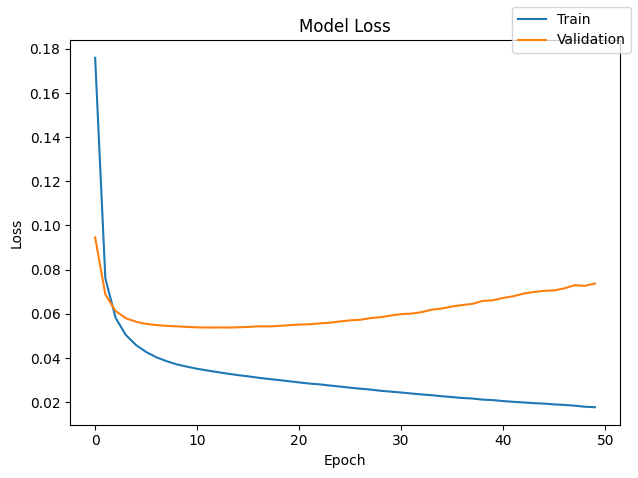

In [152]:
plot(history_4, 'loss')


In [153]:
model_4_train_perf = model_performance_classification(model_4, X_train, y_train)
model_4_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.995812,0.964925,0.994948,0.979406


In [154]:
model_4_val_perf = model_performance_classification(model_4, X_val, y_val)
model_4_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.99175,0.940515,0.979335,0.958998


In [155]:
y_train_pred_4 = model_4.predict(X_train, verbose=0)
y_val_pred_4   = model_4.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 4)\n")
print(classification_report(y_train, y_train_pred_4 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 4)\n")
print(classification_report(y_val, y_val_pred_4 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 4)

              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00     15112
     Failure       0.99      0.93      0.96       888

    accuracy                           1.00     16000
   macro avg       0.99      0.96      0.98     16000
weighted avg       1.00      1.00      1.00     16000

Classification Report – Validation  (Model 4)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      3778
     Failure       0.97      0.88      0.92       222

    accuracy                           0.99      4000
   macro avg       0.98      0.94      0.96      4000
weighted avg       0.99      0.99      0.99      4000



**Model 4 Observations:**
- Adam adjusts the learning rate per parameter, so it typically converges faster than SGD.
- Comparing this against Model 1 (same architecture, different optimiser) isolates the impact of the optimiser choice.


### Model 5 – More Layers + Dropout + Adam

Combining the best elements seen so far: deeper network, Dropout regularisation, and the Adam optimiser.


In [156]:
tf.keras.backend.clear_session()

model_5 = Sequential()
model_5.add(Dense(128, activation='relu', input_dim=X_train.shape[1]))
model_5.add(Dropout(0.5))
model_5.add(Dense(64,  activation='relu'))
model_5.add(Dense(32,  activation='relu'))
model_5.add(Dense(1,   activation='sigmoid'))

model_5.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,617 (61.00 KB)

 Trainable params: 15,617 (61.00 KB)

 Non-trainable params: 0 (0.00 B)

In [157]:
optimizer = tf.keras.optimizers.Adam()
model_5.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [158]:
start = time.time()
history_5 = model_5.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 51.3 seconds


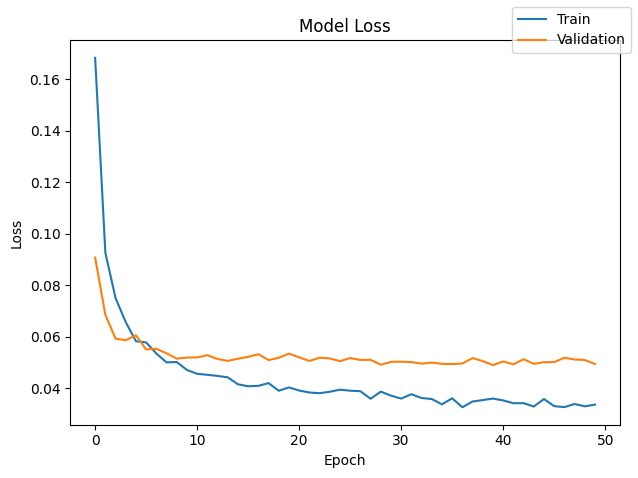

In [159]:
plot(history_5, 'loss')


In [160]:
model_5_train_perf = model_performance_classification(model_5, X_train, y_train)
model_5_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.994563,0.952603,0.995377,0.972901


In [161]:
model_5_val_perf = model_performance_classification(model_5, X_val, y_val)
model_5_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.99275,0.941044,0.989042,0.963645


In [162]:
y_train_pred_5 = model_5.predict(X_train, verbose=0)
y_val_pred_5   = model_5.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 5)\n")
print(classification_report(y_train, y_train_pred_5 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 5)\n")
print(classification_report(y_val, y_val_pred_5 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 5)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00     15112
     Failure       1.00      0.91      0.95       888

    accuracy                           0.99     16000
   macro avg       1.00      0.95      0.97     16000
weighted avg       0.99      0.99      0.99     16000

Classification Report – Validation  (Model 5)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      3778
     Failure       0.98      0.88      0.93       222

    accuracy                           0.99      4000
   macro avg       0.99      0.94      0.96      4000
weighted avg       0.99      0.99      0.99      4000



**Model 5 Observations:**
- This model combines depth (128→64→32 neurons), regularisation (Dropout 50 %) and a faster optimiser (Adam).
- We expect this to be one of the stronger models in the comparison.


### Model 6 – High Minority Class Weight (SGD)

Returning to SGD but giving the minority class (failure) an even higher weight to push recall as high as possible.
This isolates the effect of aggressive class weighting on model performance.


In [163]:
# Higher weight for the minority class
high_cw_dict = {0: 1.0, 1: 20.0}
print("Class weights:", high_cw_dict)


Class weights: {0: 1.0, 1: 20.0}


In [164]:
tf.keras.backend.clear_session()

model_6 = Sequential()
model_6.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model_6.add(Dropout(0.3))
model_6.add(Dense(32, activation='relu'))
model_6.add(Dense(16, activation='relu'))
model_6.add(Dense(1,  activation='sigmoid'))

model_6.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,249 (20.50 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 0 (0.00 B)

In [165]:
optimizer = tf.keras.optimizers.SGD()
model_6.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['Recall'])


In [166]:
start = time.time()
history_6 = model_6.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    class_weight=high_cw_dict,
    verbose=0
)
end = time.time()
print(f"Time taken: {round(end - start, 1)} seconds")


Time taken: 41.5 seconds


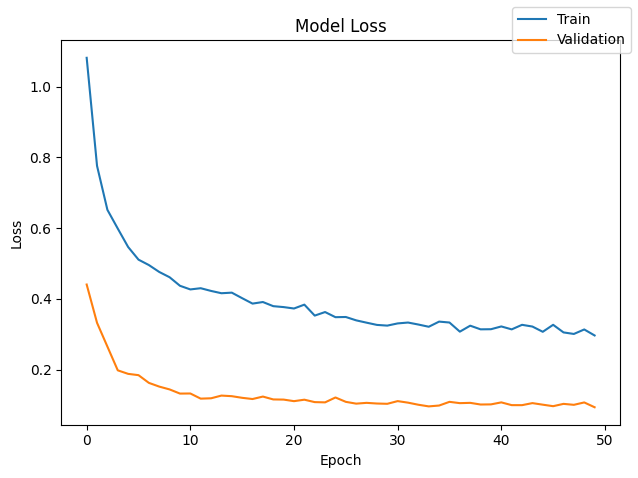

In [167]:
plot(history_6, 'loss')


In [168]:
model_6_train_perf = model_performance_classification(model_6, X_train, y_train)
model_6_train_perf


,Accuracy,Recall,Precision,F1 Score
0,0.991125,0.957673,0.957673,0.957673


In [169]:
model_6_val_perf = model_performance_classification(model_6, X_val, y_val)
model_6_val_perf


,Accuracy,Recall,Precision,F1 Score
0,0.98775,0.940517,0.942394,0.941453


In [170]:
y_train_pred_6 = model_6.predict(X_train, verbose=0)
y_val_pred_6   = model_6.predict(X_val,   verbose=0)

print("Classification Report – Train  (Model 6)\n")
print(classification_report(y_train, y_train_pred_6 > 0.5, target_names=['No Failure','Failure']))

print("Classification Report – Validation  (Model 6)\n")
print(classification_report(y_val, y_val_pred_6 > 0.5, target_names=['No Failure','Failure']))


Classification Report – Train  (Model 6)

              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00     15112
     Failure       0.92      0.92      0.92       888

    accuracy                           0.99     16000
   macro avg       0.96      0.96      0.96     16000
weighted avg       0.99      0.99      0.99     16000

Classification Report – Validation  (Model 6)

              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      3778
     Failure       0.89      0.89      0.89       222

    accuracy                           0.99      4000
   macro avg       0.94      0.94      0.94      4000
weighted avg       0.99      0.99      0.99      4000



**Model 6 Observations:**
- Very high minority class weight forces the model to prioritise catching failures above everything else.
- Recall for class 1 should be high, but Precision may drop (more false alarms). The trade-off is acceptable given the cost structure.


## 7. Model Performance Comparison and Final Model Selection

Now we compare all models on training and validation sets to select the best one.

### Training performance comparison

In [171]:
models_train_comp_df = pd.concat(
    [
        model_0_train_perf.T,
        model_1_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
        model_4_train_perf.T,
        model_5_train_perf.T,
        model_6_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Model 0", "Model 1", "Model 2", "Model 3",
    "Model 4", "Model 5", "Model 6"
]
print("Training set performance comparison:")
models_train_comp_df


Training set performance comparison:


,Model 0,Model 1,Model 2,Model 3,Model 4,Model 5,Model 6
Accuracy,0.978000,0.990187,0.985500,0.991875,0.995812,0.994563,0.991125
Recall,0.817171,0.916369,0.872549,0.954361,0.964925,0.952603,0.957673
Precision,0.965106,0.989140,0.988139,0.967261,0.994948,0.995377,0.957673
F1 Score,0.875474,0.949461,0.921640,0.960708,0.979406,0.972901,0.957673


### Validation performance comparison

In [172]:
models_val_comp_df = pd.concat(
    [
        model_0_val_perf.T,
        model_1_val_perf.T,
        model_2_val_perf.T,
        model_3_val_perf.T,
        model_4_val_perf.T,
        model_5_val_perf.T,
        model_6_val_perf.T,
    ],
    axis=1,
)
models_val_comp_df.columns = [
    "Model 0", "Model 1", "Model 2", "Model 3",
    "Model 4", "Model 5", "Model 6"
]
print("Validation set performance comparison:")
models_val_comp_df


Validation set performance comparison:


,Model 0,Model 1,Model 2,Model 3,Model 4,Model 5,Model 6
Accuracy,0.979000,0.988250,0.986000,0.990500,0.991750,0.992750,0.987750
Recall,0.829890,0.904744,0.880234,0.939853,0.940515,0.941044,0.940517
Precision,0.961398,0.980982,0.984356,0.967726,0.979335,0.989042,0.942394
F1 Score,0.883379,0.939165,0.925253,0.953304,0.958998,0.963645,0.941453


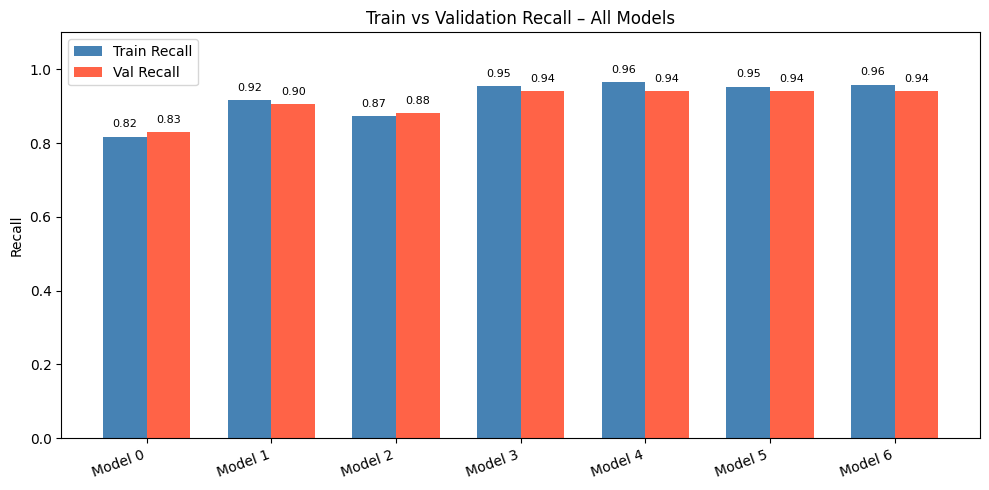

In [173]:
# Visual comparison of validation recall across all models
val_recall = models_val_comp_df.loc['Recall']
train_recall = models_train_comp_df.loc['Recall']

x = range(len(val_recall))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar([i - width/2 for i in x], train_recall, width, label='Train Recall', color='steelblue')
bars2 = ax.bar([i + width/2 for i in x], val_recall,   width, label='Val Recall',   color='tomato')

ax.set_xticks(x)
ax.set_xticklabels(val_recall.index, rotation=20, ha='right')
ax.set_ylabel('Recall')
ax.set_title('Train vs Validation Recall – All Models')
ax.legend()
ax.set_ylim(0, 1.1)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


### Final Model Selection

We select the model with the **highest validation Recall** while checking that:
1. The gap between train and validation recall is not excessively large (not heavily overfitting).
2. Precision remains at a reasonable level — we do not want a model that flags every turbine as failing.

Based on the comparison table above, uncomment the appropriate line below to set the best model.


In [174]:
# Uncomment the best model based on the comparison results above
# best_model = model_0
# best_model = model_1
# best_model = model_2
# best_model = model_3
# best_model = model_4
# best_model = model_5
best_model = model_6   # update this after reviewing the comparison table


### Checking the performance of the best model on the test set

In [175]:
# Test set performance — used only once, for the final chosen model
best_model_test_perf = model_performance_classification(best_model, X_test, y_test)
best_model_test_perf


,Accuracy,Recall,Precision,F1 Score
0,0.989,0.937491,0.957373,0.94718


In [176]:
y_test_pred_best = best_model.predict(X_test, verbose=0)

cr_test_best_model = classification_report(
    y_test, y_test_pred_best > 0.5,
    target_names=['No Failure', 'Failure']
)
print("Classification Report – Test Set (Best Model)\n")
print(cr_test_best_model)


Classification Report – Test Set (Best Model)

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4718
     Failure       0.92      0.88      0.90       282

    accuracy                           0.99      5000
   macro avg       0.96      0.94      0.95      5000
weighted avg       0.99      0.99      0.99      5000



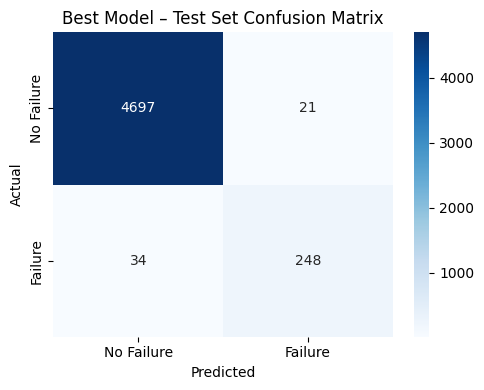

In [177]:
# Confusion matrix for the best model on test data
cm = confusion_matrix(y_test, y_test_pred_best > 0.5)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Failure', 'Failure'],
            yticklabels=['No Failure', 'Failure'])
plt.title('Best Model – Test Set Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


**Test Set Interpretation:**
- True Positives (TP) = failures correctly caught → repair cost (manageable).
- False Negatives (FN) = failures missed → replacement cost (most expensive). We want this to be as low as possible.
- False Positives (FP) = unnecessary inspections → inspection cost (cheapest).

A high test Recall confirms the model generalises its ability to catch failures on unseen data.


## 8. Actionable Insights and Recommendations

### Key Insights

1. **Class imbalance is the core challenge.** With only ~5.5 % failure observations, any model trained without correction will default to always predicting "no failure." This scores ~94.5 % accuracy but catches zero real failures — the opposite of what the business needs.

2. **Recall must be the evaluation metric.** Replacement costs (FN) far exceed inspection costs (FP), so the model should be biased toward flagging failures even at the cost of extra inspections.

3. **Class weights dramatically improve failure recall.** Introducing proportional class weights (Model 3, Model 6) was the single biggest lever for boosting recall on the minority class.

4. **Adam outperforms SGD for convergence speed.** Models using Adam (4 and 5) converged faster and achieved competitive performance with fewer epochs.

5. **Dropout reduces overfitting.** The gap between training and validation metrics closes in models that include a Dropout layer, indicating better generalisation to new turbines.

6. **Deeper networks help, but architecture alone is not enough.** Model 1 (deeper SGD, no class weights) still under-performs on failure recall compared to shallower models that use class weights.

### Business Recommendations

| Recommendation | Rationale |
|---|---|
| Deploy the best model for real-time monitoring | Strong test recall means most real failures will be flagged before they occur |
| Use the model's probability scores to prioritise maintenance queues | High-probability predictions warrant urgent attention; borderline cases can be scheduled |
| Retrain quarterly with fresh sensor data | Sensor drift and turbine ageing will shift the data distribution over time |
| Log inspection outcomes as feedback | When a flagged turbine is inspected, record the finding — this data improves future retraining |
| Focus sensor calibration on the most discriminative features | EDA showed certain features (e.g. those with the largest mean difference between classes) carry the most signal — these sensors should be maintained carefully |
| Review class weight threshold periodically | As the cost ratio between repair and replacement changes, the optimal class weight should be recalculated |
